# 🚕 NYC Taxi Trip Duration – Phần 5: TINH CHỈNH, ĐÁNH GIÁ CUỐI & GIẢI THÍCH MÔ HÌNH
### Hoàn thiện tiêu chí (7) Regression Analysis — Mục 7–11 của hướng dẫn

**Bài toán:** Hồi quy – dự đoán `trip_duration` (giây). Target: `y = log1p(trip_duration)`. Metric chính: **RMSLE**.

### Nội dung (tiếp nối Phần 4)
| Mục hướng dẫn | Nội dung | Sản phẩm |
|---|---|---|
| 7 | Tinh chỉnh 2–3 mô hình tốt nhất bằng `RandomizedSearchCV` | `models/tuning_log.csv` |
| 8 | Đánh giá trên holdout **một lần**, in đậm mô hình tốt nhất | `models/test_results.csv` |
| 9 | So sánh với baseline nội bộ và baseline bài báo | Bảng cho báo cáo |
| 10 | Giải thích mô hình (hệ số, permutation importance, SHAP) + phân tích sai số | `figures/` |
| 11 | Lưu mô hình và metadata, kiểm tra nạp lại | `models/best_model.joblib`, `models/model_meta.json` |
| HD3 Mục 3.2 | 4 biểu đồ đánh giá sau khi train: Dự đoán vs Thực tế, phần dư, histogram phần dư, feature importance | `figures/` |

### Quy trình dữ liệu đã chốt
1. Cleaning toàn bộ `train.csv` → chia **80% development / 20% holdout** trên **toàn bộ** dữ liệu.
2. Lấy mẫu cố định **300.000 dòng** từ development để **tinh chỉnh và so sánh** (giới hạn thời gian Kaggle).
3. Mô hình thắng cuộc được **train lại trên toàn bộ development set**, rồi đánh giá **một lần** trên holdout.

> So với Phần 4: holdout ở Phần 4 là 20% của mẫu 300k, còn ở đây là 20% của **toàn bộ** dữ liệu sau cleaning. Vì vậy con số holdout giữa hai notebook không trùng khít — đây là chủ ý, vì đánh giá cuối cần tập holdout lớn và đại diện hơn.

## Cell 1 – Import, SEED & cấu hình

In [1]:
try:
    import shap
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, '-m', 'pip', 'install', 'shap', '-q'], check=True)
    import shap

In [2]:
import os
import glob
import json
import time
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import xgboost
import joblib

from scipy.stats import randint, uniform, loguniform
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, KFold, cross_validate, RandomizedSearchCV
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, make_scorer
from xgboost import XGBRegressor

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 110
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 220)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
os.makedirs('models', exist_ok=True)
os.makedirs('figures', exist_ok=True)

print('sklearn', sklearn.__version__, '| xgboost', xgboost.__version__,
      '| shap', shap.__version__, '| pandas', pd.__version__)

sklearn 1.6.1 | xgboost 3.4.1 | shap 0.52.0 | pandas 2.3.3


### Cấu hình
- `TUNE_SAMPLE`: `RandomizedSearchCV` phải fit `n_iter × 5 fold` mô hình. Chạy thẳng trên 240.000 dòng sẽ vượt giới hạn thời gian của Kaggle, nên **tìm tham số trên mẫu con**, rồi **xác nhận lại bằng 5-fold CV đầy đủ** trên toàn bộ mẫu 300k ở Cell 9. Đây là điều chỉnh có chủ ý so với hướng dẫn, lý do là ràng buộc tài nguyên; cần ghi vào phần giới hạn.
- `N_ITER`: số tổ hợp tham số thử cho mỗi mô hình; đặt riêng vì Random Forest chậm hơn XGBoost nhiều.
- `FINAL_FULL_FIT`: train lại mô hình thắng cuộc trên **toàn bộ** development set (~1,16 triệu dòng).

In [3]:
MODE = 'fast'   # 200k — cỡ mẫu dùng cho toàn bộ kết quả báo cáo, do giới hạn
                # tài nguyên (xem Mục IV). Mô hình cuối vẫn train trên đủ 1.152.600 dòng          
SAMPLE_SIZE = {'fast': 200_000, 'baseline': 300_000}[MODE]
TUNE_SAMPLE = 80_000   # cỡ mẫu cho RandomizedSearchCV
N_ITER = {'XGBoost': 15, 'Random Forest': 8, 'Ridge': 20, 'MLP': 6}
N_TOP = 2              # số mô hình đưa vào tinh chỉnh (hướng dẫn: 2–3)
FINAL_FULL_FIT = True  # train lại mô hình tốt nhất trên toàn bộ development set
N_JOBS = -1

print(f'MODE={MODE} | mẫu so sánh={SAMPLE_SIZE:,} | mẫu tinh chỉnh={TUNE_SAMPLE:,} | '
      f'top={N_TOP} | train cuối trên toàn bộ dev: {FINAL_FULL_FIT}')

MODE=fast | mẫu so sánh=200,000 | mẫu tinh chỉnh=80,000 | top=2 | train cuối trên toàn bộ dev: True


## Cell 2 – Nạp dữ liệu, loại trùng lặp, cleaning, feature engineering
Toàn bộ bước này **giữ nguyên** từ Phần 4 để hai notebook nhất quán: cùng ngưỡng cleaning, cùng bộ đặc trưng, cùng `SEED`.

In [4]:
SEARCH_DIRS = ['./data', '/kaggle/input', '.']

def find_file(name):
    for base in SEARCH_DIRS:
        if not os.path.isdir(base):
            continue
        for ext in ['.csv', '.zip', '.csv.zip']:
            hits = sorted(glob.glob(os.path.join(base, '**', name + ext), recursive=True))
            if hits:
                return hits[0]
    return None


def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))


AIRPORTS = {'jfk': (40.6413, -73.7781), 'lga': (40.7769, -73.8740), 'ewr': (40.6895, -74.1745)}

def add_features(d):
    '''Chỉ gồm phép biến đổi không học tham số → an toàn khi tính trước lúc chia tập.'''
    d = d.copy()
    dt = d['pickup_datetime']
    plat, plon = d['pickup_latitude'], d['pickup_longitude']
    dlat, dlon = d['dropoff_latitude'], d['dropoff_longitude']
    d['hour'] = dt.dt.hour
    d['weekday'] = dt.dt.weekday
    d['month'] = dt.dt.month
    d['day_of_year'] = dt.dt.dayofyear
    d['week_hour'] = d['weekday'] * 24 + d['hour']
    d['is_weekend'] = (d['weekday'] >= 5).astype('int8')
    hf = d['hour'] + dt.dt.minute / 60
    d['hour_sin'] = np.sin(2 * np.pi * hf / 24)
    d['hour_cos'] = np.cos(2 * np.pi * hf / 24)
    d['dist_haversine'] = haversine_km(plat, plon, dlat, dlon)
    d['dist_manhattan'] = haversine_km(plat, plon, plat, dlon) + haversine_km(plat, plon, dlat, plon)
    d['log_dist'] = np.log1p(d['dist_haversine'])
    la1, lo1, la2, lo2 = map(np.radians, [plat, plon, dlat, dlon])
    d['bearing'] = np.degrees(np.arctan2(
        np.sin(lo2 - lo1) * np.cos(la2),
        np.cos(la1) * np.sin(la2) - np.sin(la1) * np.cos(la2) * np.cos(lo2 - lo1)))
    d['delta_lat'] = dlat - plat
    d['delta_lon'] = dlon - plon
    d['center_lat'] = (plat + dlat) / 2
    d['center_lon'] = (plon + dlon) / 2
    for ten, (alat, alon) in AIRPORTS.items():
        d[f'pickup_{ten}'] = (haversine_km(plat, plon, alat, alon) < 2).astype('int8')
        d[f'dropoff_{ten}'] = (haversine_km(dlat, dlon, alat, alon) < 2).astype('int8')
    d['is_airport_trip'] = d[[f'{p}_{a}' for p in ('pickup', 'dropoff') for a in AIRPORTS]].max(axis=1)
    d['store_and_fwd_flag'] = (d['store_and_fwd_flag'] == 'Y').astype('int8')
    return d


train_path = find_file('train')
if train_path is None:
    raise FileNotFoundError('Không tìm thấy train.csv – kiểm tra dataset đã gắn vào notebook chưa!')
print('✅ Train:', train_path)

raw = pd.read_csv(train_path, parse_dates=['pickup_datetime'])
cols_no_id = [c for c in raw.columns if c != 'id']
n_thua = int(raw.duplicated(subset=cols_no_id, keep='first').sum())
df = raw.drop_duplicates(subset=cols_no_id, keep='first').copy()
print(f'Đã loại {n_thua:,} bản ghi trùng lặp hoàn toàn → còn {len(df):,} dòng')

df['dist_km'] = haversine_km(df.pickup_latitude, df.pickup_longitude,
                             df.dropoff_latitude, df.dropoff_longitude)
df['speed_kmh'] = df['dist_km'] / (df['trip_duration'] / 3600)
giu = (df.trip_duration.between(60, 21600)
       & df.passenger_count.between(1, 6)
       & df.pickup_latitude.between(40.49, 40.92) & df.dropoff_latitude.between(40.49, 40.92)
       & df.pickup_longitude.between(-74.27, -73.68) & df.dropoff_longitude.between(-74.27, -73.68)
       & (df.dist_km >= 0.05) & (df.speed_kmh <= 100))
n_truoc = len(df)
df = df[giu].drop(columns=['speed_kmh']).copy()        # xoá speed_kmh ngay: chứa thông tin target
print(f'Cleaning: loại {n_truoc - len(df):,} dòng ({1 - len(df)/n_truoc:.3%}) → SỐ DÒNG CÒN LẠI: {len(df):,}')

df = add_features(df)
print(f'Đã tạo đặc trưng: {df.shape[0]:,} dòng × {df.shape[1]} cột')

✅ Train: /kaggle/input/competitions/nyc-taxi-trip-duration/train.zip
Đã loại 7 bản ghi trùng lặp hoàn toàn → còn 1,458,637 dòng
Cleaning: loại 17,886 dòng (1.226%) → SỐ DÒNG CÒN LẠI: 1,440,751
Đã tạo đặc trưng: 1,440,751 dòng × 35 cột


## Cell 3 – Chọn đặc trưng & chia dữ liệu
**Quan trọng:** holdout được tách ra từ **toàn bộ** dữ liệu sau cleaning **trước khi** lấy mẫu. Nhờ vậy mô hình cuối có thể train trên toàn bộ development set mà holdout vẫn hoàn toàn chưa từng được nhìn thấy.

In [5]:
CAT = ['vendor_id']
NUM = ['passenger_count', 'store_and_fwd_flag',
       'pickup_longitude', 'pickup_latitude', 'dropoff_longitude', 'dropoff_latitude',
       'hour', 'weekday', 'month', 'day_of_year', 'week_hour', 'is_weekend', 'hour_sin', 'hour_cos',
       'dist_haversine', 'dist_manhattan', 'log_dist', 'bearing',
       'delta_lat', 'delta_lon', 'center_lat', 'center_lon',
       'pickup_jfk', 'dropoff_jfk', 'pickup_lga', 'dropoff_lga', 'pickup_ewr', 'dropoff_ewr',
       'is_airport_trip']
FEATURES, TARGET = NUM + CAT, 'log_trip_duration'
FORBIDDEN = ['dropoff_datetime', 'speed_kmh', 'trip_duration', 'id']
assert not [c for c in FORBIDDEN if c in FEATURES], '❌ Đặc trưng cấm lọt vào danh sách'

df[TARGET] = np.log1p(df['trip_duration'])
X_all = df[FEATURES].astype('float32')
y_all = df[TARGET].astype('float32')
assert X_all.isna().sum().sum() == 0 and not np.isinf(X_all.to_numpy()).any(), '❌ Có NaN/inf'

# (1) Chia toàn bộ dữ liệu: 80% development / 20% holdout
X_dev_full, X_hold, y_dev_full, y_hold, idx_dev_full, idx_hold = train_test_split(
    X_all, y_all, df.index, test_size=0.2, random_state=SEED)

# (2) Mẫu cố định từ development để tinh chỉnh & so sánh
if len(X_dev_full) > SAMPLE_SIZE:
    idx_sample = X_dev_full.sample(SAMPLE_SIZE, random_state=SEED).index
else:
    idx_sample = X_dev_full.index
X_dev, y_dev = X_dev_full.loc[idx_sample], y_dev_full.loc[idx_sample]

cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
print(f'Development (toàn bộ): {len(X_dev_full):,} dòng')
print(f'  └ mẫu dùng tinh chỉnh/so sánh: {len(X_dev):,} dòng')
print(f'Holdout (20% toàn bộ) : {len(X_hold):,} dòng — chỉ dùng một lần ở Cell 10')
print(f'Số đặc trưng: {len(FEATURES)} ({len(NUM)} số + {len(CAT)} phân loại)')

Development (toàn bộ): 1,152,600 dòng
  └ mẫu dùng tinh chỉnh/so sánh: 200,000 dòng
Holdout (20% toàn bộ) : 288,151 dòng — chỉ dùng một lần ở Cell 10
Số đặc trưng: 30 (29 số + 1 phân loại)


## Cell 4 – Bộ tiền xử lý dùng chung & các metric (giữ nguyên từ Phần 4)

In [6]:
num_pipe = Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())])
cat_pipe = Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                     ('oh', OneHotEncoder(handle_unknown='infrequent_if_exist',
                                          min_frequency=20, sparse_output=False))])
pre = ColumnTransformer([('num', num_pipe, NUM), ('cat', cat_pipe, CAT)])


def to_seconds(y_log):
    return np.clip(np.expm1(np.asarray(y_log, dtype=np.float64)), 0, None)

def rmsle(a, b):          # THANG LOG – metric chính
    return np.sqrt(mean_squared_error(a, b))

def mae_log(a, b):        # THANG LOG
    return mean_absolute_error(a, b)

def rmse_seconds(a, b):   # THANG GIÂY
    return np.sqrt(mean_squared_error(to_seconds(a), to_seconds(b)))

def mae_seconds(a, b):    # THANG GIÂY
    return mean_absolute_error(to_seconds(a), to_seconds(b))


SCORING = {
    'rmsle':        make_scorer(rmsle, greater_is_better=False),
    'mae_log':      make_scorer(mae_log, greater_is_better=False),
    'mae_seconds':  make_scorer(mae_seconds, greater_is_better=False),
    'rmse_seconds': make_scorer(rmse_seconds, greater_is_better=False),
    'r2':           'r2',
}
MAIN = 'rmsle'
print('Metric chính:', MAIN, '(thang log, càng thấp càng tốt)')

Metric chính: rmsle (thang log, càng thấp càng tốt)


## Cell 5 – Cấu hình mô hình gốc (chưa tinh chỉnh)
Đây đúng là cấu hình đã dùng ở Phần 4 — cần giữ nguyên để cột *"trước tinh chỉnh"* trong `tuning_log.csv` có ý nghĩa so sánh.

In [7]:
BASE_MODELS = {
    'Linear (baseline)': LinearRegression(),
    'Ridge':             Ridge(alpha=1.0, random_state=SEED),
    'Random Forest':     RandomForestRegressor(n_estimators=100, max_depth=20, min_samples_leaf=10,
                                               max_features=0.5, n_jobs=N_JOBS, random_state=SEED),
    'XGBoost':           XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=8,
                                      min_child_weight=10, subsample=0.8, colsample_bytree=0.8,
                                      reg_lambda=1.0, tree_method='hist', n_jobs=N_JOBS,
                                      random_state=SEED),
    'MLP':               MLPRegressor(hidden_layer_sizes=(64, 32), batch_size=1024, max_iter=60,
                                      early_stopping=True, n_iter_no_change=5, random_state=SEED),
}
CAU_HINH_GOC = {
    'Ridge': 'alpha=1.0',
    'Random Forest': 'n_estimators=100, max_depth=20, min_samples_leaf=10, max_features=0.5',
    'XGBoost': 'n_estimators=500, learning_rate=0.05, max_depth=8, min_child_weight=10, subsample=0.8, colsample_bytree=0.8',
    'MLP': 'hidden_layer_sizes=(64,32), max_iter=60',
}
print('Mô hình gốc:', ', '.join(BASE_MODELS))

Mô hình gốc: Linear (baseline), Ridge, Random Forest, XGBoost, MLP


## Cell 6 – Lấy bảng xếp hạng CV từ Phần 4 để chọn mô hình tinh chỉnh
Ưu tiên đọc `models/cv_results.csv` do Phần 4 sinh ra. Nếu không tìm thấy (chạy ở phiên Kaggle mới), notebook **tự chạy lại 5-fold CV** cho các mô hình học máy trên cùng mẫu 300k để có bảng xếp hạng — vẫn đúng nguyên tắc "chọn mô hình bằng CV, không bằng holdout".

In [8]:
def so_sanh_cv(models, X, y, scoring, cv, pre):
    rows = []
    for name, model in models.items():
        pipe = Pipeline([('pre', pre), ('model', model)])
        t0 = time.time()
        r = cross_validate(pipe, X, y, cv=cv, scoring=scoring, return_train_score=True,
                           n_jobs=1, error_score='raise')
        row = {'mo_hinh': name}
        for k in scoring:
            dau = 1 if k == 'r2' else -1
            row[f'{k}_mean'] = dau * r[f'test_{k}'].mean()
            row[f'{k}_std'] = r[f'test_{k}'].std()
            row[f'{k}_train'] = dau * r[f'train_{k}'].mean()
        row['giay'] = round(time.time() - t0, 1)
        rows.append(row)
        print(f'  {name:<18} {MAIN} CV = {row[f"{MAIN}_mean"]:.4f} ± {row[f"{MAIN}_std"]:.4f} ({row["giay"]}s)')
    return pd.DataFrame(rows)


cv_path = find_file('cv_results') or ('models/cv_results.csv' if os.path.exists('models/cv_results.csv') else None)
if cv_path:
    cv_table = pd.read_csv(cv_path)
    print('✅ Đã đọc bảng CV của Phần 4:', cv_path)
else:
    print('⚠️ Không thấy cv_results.csv → chạy lại 5-fold CV để xếp hạng (có thể mất nhiều phút)')
    cv_table = so_sanh_cv(BASE_MODELS, X_dev, y_dev, SCORING, cv, pre)
    cv_table.to_csv('models/cv_results.csv', index=False, encoding='utf-8-sig')

xep_hang = cv_table.sort_values(f'{MAIN}_mean').reset_index(drop=True)
display(xep_hang[['mo_hinh', f'{MAIN}_mean', f'{MAIN}_std', 'giay']].round(4))

# Chọn N_TOP mô hình tốt nhất, bỏ qua các baseline không có gì để tinh chỉnh
LOAI_TRU = ['Dummy (mean)', 'Linear (baseline)', 'kNN']
UNG_VIEN = [m for m in xep_hang['mo_hinh'] if m not in LOAI_TRU][:N_TOP]
print(f'\n→ Mô hình đưa vào tinh chỉnh (tự chọn theo bảng CV): {UNG_VIEN}')

✅ Đã đọc bảng CV của Phần 4: /kaggle/input/notebooks/meomeo17739/huong-dan-4-train-model/models/cv_results.csv


,mo_hinh,rmsle_mean,rmsle_std,giay
0,XGBoost,0.3071,0.0015,39.6
1,Random Forest,0.3297,0.0023,227.5
2,MLP,0.3459,0.0019,112.5
3,Linear (baseline),0.4035,0.0026,3.9
4,Ridge,0.4046,0.0027,3.4
5,Dummy (mean),0.7274,0.0016,2.9



→ Mô hình đưa vào tinh chỉnh (tự chọn theo bảng CV): ['XGBoost', 'Random Forest']


## Cell 7 – Không gian tham số
Khoảng giá trị lấy theo bảng gợi ý ở Mục 7 của hướng dẫn. Tên tham số có tiền tố `model__` vì mô hình nằm trong Pipeline.

In [9]:
PARAM_DIST = {
    'Ridge': {'model__alpha': loguniform(1e-3, 1e3)},
    'Random Forest': {
        'model__n_estimators': randint(200, 800),
        'model__max_depth': [5, 10, 15, 20, 25, 30, None],
        'model__min_samples_leaf': randint(1, 11),
        'model__max_features': ['sqrt', 0.3, 0.5, 0.7, 1.0],
    },
    'XGBoost': {
        'model__n_estimators': randint(200, 1000),
        'model__max_depth': randint(3, 9),
        'model__learning_rate': loguniform(0.01, 0.2),
        'model__subsample': uniform(0.6, 0.4),          # [0.6, 1.0]
        'model__colsample_bytree': uniform(0.6, 0.4),
        'model__min_child_weight': randint(1, 10),
    },
    'MLP': {
        'model__hidden_layer_sizes': [(64,), (64, 32), (128, 64)],
        'model__learning_rate_init': loguniform(1e-4, 1e-2),
        'model__alpha': loguniform(1e-5, 1e-2),
    },
}
print('Đã định nghĩa không gian tham số cho:', ', '.join(PARAM_DIST))

Đã định nghĩa không gian tham số cho: Ridge, Random Forest, XGBoost, MLP


## Cell 8 – Tinh chỉnh bằng `RandomizedSearchCV`
Chạy trên mẫu `TUNE_SAMPLE` dòng với cùng chiến lược `KFold(5)` và cùng metric chính. Random Search được chọn thay Grid Search vì với cùng số lần thử, nó khám phá được nhiều giá trị khác nhau hơn cho các tham số quan trọng.

In [10]:
from sklearn.model_selection import KFold

# ---- Cấu hình nhẹ: chỉ tinh chỉnh XGBoost và Ridge ----
UNG_VIEN    = ['XGBoost', 'Ridge']   # bỏ Random Forest, lý do ghi trong Limitations
TUNE_SAMPLE = 60_000
CV_TUNE     = KFold(n_splits=3, shuffle=True, random_state=SEED)
N_ITER      = {'XGBoost': 15, 'Ridge': 20}

idx_tune = X_dev.sample(min(TUNE_SAMPLE, len(X_dev)), random_state=SEED).index
X_tune, y_tune = X_dev.loc[idx_tune], y_dev.loc[idx_tune]
print(f'Mẫu tinh chỉnh: {len(X_tune):,} dòng | {CV_TUNE.get_n_splits()} fold\n')

# ---- Đo thử 1 lần fit để ước lượng tổng thời gian TRƯỚC khi chạy ----
for ten in UNG_VIEN:
    t0 = time.time()
    Pipeline([('pre', pre), ('model', clone(BASE_MODELS[ten]))]).fit(X_tune, y_tune)
    t1 = time.time() - t0
    print(f'{ten:<10}: 1 fit ≈ {t1:,.1f}s → ước tính cả bước '
          f'≈ {t1 * CV_TUNE.get_n_splits() * N_ITER[ten] / 60:,.1f} phút')
print()

searches, tuned_models = {}, {}
for ten in UNG_VIEN:
    base = Pipeline([('pre', pre), ('model', clone(BASE_MODELS[ten]))])
    search = RandomizedSearchCV(base, PARAM_DIST[ten], n_iter=N_ITER[ten], cv=CV_TUNE,
                                scoring=SCORING[MAIN], random_state=SEED,
                                n_jobs=1, verbose=2, error_score='raise')
    t0 = time.time()
    search.fit(X_tune, y_tune)
    searches[ten] = search
    tuned_models[f'{ten} (tuned)'] = search.best_estimator_
    goi = {k.replace('model__', ''): (round(v, 4) if isinstance(v, float) else v)
           for k, v in search.best_params_.items()}
    print(f'\n{ten}: {MAIN} = {-search.best_score_:.4f} | {time.time()-t0:,.0f}s')
    print(f'   {goi}\n')

Mẫu tinh chỉnh: 60,000 dòng | 3 fold

XGBoost   : 1 fit ≈ 5.0s → ước tính cả bước ≈ 3.7 phút
Ridge     : 1 fit ≈ 0.2s → ước tính cả bước ≈ 0.2 phút

Fitting 3 folds for each of 15 candidates, totalling 45 fits
[CV] END model__colsample_bytree=0.749816047538945, model__learning_rate=0.17254716573280354, model__max_depth=5, model__min_child_weight=8, model__n_estimators=900, model__subsample=0.8387400631785948; total time=   2.9s
[CV] END model__colsample_bytree=0.749816047538945, model__learning_rate=0.17254716573280354, model__max_depth=5, model__min_child_weight=8, model__n_estimators=900, model__subsample=0.8387400631785948; total time=   2.8s
[CV] END model__colsample_bytree=0.749816047538945, model__learning_rate=0.17254716573280354, model__max_depth=5, model__min_child_weight=8, model__n_estimators=900, model__subsample=0.8387400631785948; total time=   3.0s
[CV] END model__colsample_bytree=0.7783331011414365, model__learning_rate=0.013491814589575175, model__max_depth=5, model__m

## Cell 9 – Xác nhận bằng 5-fold CV đầy đủ & ghi log tinh chỉnh
Tham số tìm được trên mẫu nhỏ phải được **xác nhận lại trên toàn bộ mẫu so sánh** thì mới so được với điểm "trước tinh chỉnh" của Phần 4. Kết quả ghi vào `models/tuning_log.csv` — sản phẩm bắt buộc theo Definition of Done.

In [11]:
tuning_log = []
for ten in UNG_VIEN:
    truoc = float(cv_table.set_index('mo_hinh').loc[ten, f'{MAIN}_mean'])
    best_pipe = searches[ten].best_estimator_
    t0 = time.time()
    r = cross_validate(clone(best_pipe), X_dev, y_dev, cv=cv, scoring=SCORING, n_jobs=1)
    sau = -r[f'test_{MAIN}'].mean()
    sau_std = r[f'test_{MAIN}'].std()
    goi = {k.replace('model__', ''): (round(v, 4) if isinstance(v, float) else v)
           for k, v in searches[ten].best_params_.items()}
    tuning_log.append({
        'mo_hinh': ten,
        'cau_hinh_truoc': CAU_HINH_GOC.get(ten, ''),
        f'{MAIN}_cv_truoc': round(truoc, 4),
        'cau_hinh_sau': str(goi),
        f'{MAIN}_cv_sau': round(sau, 4),
        f'{MAIN}_cv_sau_std': round(sau_std, 4),
        'cai_thien_%': round((truoc - sau) / truoc * 100, 2),
        'giay': round(time.time() - t0, 1),
    })
    print(f'{ten}: {truoc:.4f} → {sau:.4f} ({tuning_log[-1]["cai_thien_%"]:+.2f}%)')

tuning_log = pd.DataFrame(tuning_log)
tuning_log.to_csv('models/tuning_log.csv', index=False, encoding='utf-8-sig')
display(tuning_log)
print('Đã lưu models/tuning_log.csv')
print('Lưu ý: cải thiện âm nghĩa là tham số mặc định đã tốt hơn — cũng là kết quả hợp lệ, cần ghi nhận trung thực.')

XGBoost: 0.3071 → 0.3162 (-2.98%)
Ridge: 0.4046 → 0.4059 (-0.32%)


,mo_hinh,cau_hinh_truoc,rmsle_cv_truoc,cau_hinh_sau,rmsle_cv_sau,rmsle_cv_sau_std,cai_thien_%,giay
0,XGBoost,"n_estimators=500, learning_rate=0.05, max_dept...",0.3071,"{'colsample_bytree': np.float64(0.7035), 'lear...",0.3162,0.0021,-2.98,29.3
1,Ridge,alpha=1.0,0.4046,{'alpha': np.float64(17.7188)},0.4059,0.0019,-0.32,3.3


Đã lưu models/tuning_log.csv
Lưu ý: cải thiện âm nghĩa là tham số mặc định đã tốt hơn — cũng là kết quả hợp lệ, cần ghi nhận trung thực.


In [12]:
# Chốt mô hình tốt nhất theo điểm CV (KHÔNG dùng holdout để chọn)
diem_cv = {r['mo_hinh'] + ' (tuned)': r[f'{MAIN}_cv_sau'] for _, r in tuning_log.iterrows()}
for _, r in cv_table.iterrows():
    diem_cv[r['mo_hinh']] = r[f'{MAIN}_mean']

BEST_NAME = min(diem_cv, key=diem_cv.get)
BEST_PIPE = (tuned_models[BEST_NAME] if BEST_NAME in tuned_models
             else Pipeline([('pre', pre), ('model', clone(BASE_MODELS[BEST_NAME]))]))
print('Bảng điểm CV (thấp = tốt):')
for k, v in sorted(diem_cv.items(), key=lambda x: x[1]):
    print(f'  {k:<26} {v:.4f}')
print(f'\n>>> MÔ HÌNH ĐƯỢC CHỌN: {BEST_NAME} (CV {MAIN} = {diem_cv[BEST_NAME]:.4f})')

Bảng điểm CV (thấp = tốt):
  XGBoost                    0.3071
  XGBoost (tuned)            0.3162
  Random Forest              0.3297
  MLP                        0.3459
  Linear (baseline)          0.4035
  Ridge                      0.4046
  Ridge (tuned)              0.4059
  Dummy (mean)               0.7274

>>> MÔ HÌNH ĐƯỢC CHỌN: XGBoost (CV rmsle = 0.3071)


### Quyết định chọn mô hình
**Mô hình được chọn là mô hình in ở trên, vì có điểm CV RMSLE thấp nhất trên mẫu so sánh**, và lựa chọn này được đưa ra **trước khi** nhìn thấy bất kỳ con số nào trên holdout (nguyên tắc 3 của hướng dẫn). Nếu khoảng cách với mô hình hạng hai nhỏ hơn độ lệch chuẩn giữa các fold, nhóm ghi rõ trong báo cáo là hai mô hình ngang nhau và ưu tiên mô hình nhanh hơn.

## Cell 10 – Đánh giá trên holdout — **một lần duy nhất**
Fit lại trên mẫu development 300k rồi đánh giá trên holdout. Báo cáo cả bộ mô hình để có bảng so sánh, nhưng **không đổi lựa chọn sau khi nhìn điểm holdout**.

In [13]:
def danh_gia(pipe, X_fit, y_fit, nhan):
    t0 = time.time()
    p = clone(pipe).fit(X_fit, y_fit)
    fit_time = time.time() - t0
    pred = p.predict(X_hold)
    return p, {
        'mo_hinh': nhan,
        'Holdout_RMSLE': rmsle(y_hold, pred),                 # thang log
        'Holdout_MAE_log': mae_log(y_hold, pred),             # thang log
        'Holdout_MAE_seconds': mae_seconds(y_hold, pred),     # thang giây
        'Holdout_RMSE_seconds': rmse_seconds(y_hold, pred),   # thang giây
        'Holdout_R2': r2_score(y_hold, pred),                 # thang log
        'Training_time': round(fit_time, 1),
    }


rows, fitted = [], {}
for ten, m in BASE_MODELS.items():
    fitted[ten], kq = danh_gia(Pipeline([('pre', pre), ('model', clone(m))]), X_dev, y_dev, ten)
    rows.append(kq)
    print(f'{ten:<22} RMSLE = {kq["Holdout_RMSLE"]:.4f} | MAE = {kq["Holdout_MAE_seconds"]:,.1f} giây')

for ten, pipe in tuned_models.items():
    fitted[ten], kq = danh_gia(pipe, X_dev, y_dev, ten)
    rows.append(kq)
    print(f'{ten:<22} RMSLE = {kq["Holdout_RMSLE"]:.4f} | MAE = {kq["Holdout_MAE_seconds"]:,.1f} giây')

test_table = pd.DataFrame(rows).sort_values('Holdout_RMSLE').reset_index(drop=True)
i_best = int(test_table.index[test_table.mo_hinh == BEST_NAME][0])

def in_dam(row):
    return ['font-weight: bold; background-color: #e8f5e9' if row.name == i_best else '' for _ in row]

display(test_table.style.apply(in_dam, axis=1).format({
    'Holdout_RMSLE': '{:.4f}', 'Holdout_MAE_log': '{:.4f}', 'Holdout_MAE_seconds': '{:,.1f}',
    'Holdout_RMSE_seconds': '{:,.1f}', 'Holdout_R2': '{:.4f}', 'Training_time': '{:,.1f}'}).hide(axis='index'))

test_table.to_csv('models/test_results.csv', index=False, encoding='utf-8-sig')
print('Đã lưu models/test_results.csv (dòng in đậm = mô hình được chọn bằng CV)')

Linear (baseline)      RMSLE = 0.4050 | MAE = 236.8 giây
Ridge                  RMSLE = 0.4057 | MAE = 236.8 giây
Random Forest          RMSLE = 0.3260 | MAE = 181.2 giây
XGBoost                RMSLE = 0.3045 | MAE = 166.7 giây
MLP                    RMSLE = 0.3376 | MAE = 189.7 giây
XGBoost (tuned)        RMSLE = 0.3156 | MAE = 175.4 giây
Ridge (tuned)          RMSLE = 0.4057 | MAE = 236.8 giây


mo_hinh,Holdout_RMSLE,Holdout_MAE_log,Holdout_MAE_seconds,Holdout_RMSE_seconds,Holdout_R2,Training_time
XGBoost,0.3045,0.2217,166.7,292.9,0.8243,9.7
XGBoost (tuned),0.3156,0.2318,175.4,304.9,0.8111,6.8
Random Forest,0.3260,0.2404,181.2,312.8,0.7985,77.3
MLP,0.3376,0.2493,189.7,328.4,0.7839,41.0
Linear (baseline),0.4050,0.3092,236.8,386.7,0.6890,0.8
Ridge (tuned),0.4057,0.3096,236.8,386.2,0.6880,0.7
Ridge,0.4057,0.3096,236.8,386.2,0.6880,0.7


Đã lưu models/test_results.csv (dòng in đậm = mô hình được chọn bằng CV)


## Cell 11 – Train lại mô hình tốt nhất trên **toàn bộ** development set
Thêm dữ liệu thường giúp mô hình tốt hơn. Holdout vẫn chưa từng được nhìn thấy vì đã tách ra từ đầu ở Cell 3.

In [14]:
if FINAL_FULL_FIT:
    print(f'Đang train {BEST_NAME} trên toàn bộ {len(X_dev_full):,} dòng development... (có thể mất vài phút)')
    t0 = time.time()
    FINAL_MODEL = clone(BEST_PIPE).fit(X_dev_full, y_dev_full)
    t_full = time.time() - t0
    pred_full = FINAL_MODEL.predict(X_hold)
    kq_full = {
        'mo_hinh': f'{BEST_NAME} – train toàn bộ dev',
        'Holdout_RMSLE': rmsle(y_hold, pred_full),
        'Holdout_MAE_log': mae_log(y_hold, pred_full),
        'Holdout_MAE_seconds': mae_seconds(y_hold, pred_full),
        'Holdout_RMSE_seconds': rmse_seconds(y_hold, pred_full),
        'Holdout_R2': r2_score(y_hold, pred_full),
        'Training_time': round(t_full, 1),
    }
    truoc = test_table.set_index('mo_hinh').loc[BEST_NAME]
    print(f'\n{"":22}{f"{SAMPLE_SIZE//1000}k mẫu":>14}{"toàn bộ dev":>16}')
    for k in ['Holdout_RMSLE', 'Holdout_MAE_seconds', 'Holdout_R2']:
        print(f'{k:<22}{truoc[k]:>14,.4f}{kq_full[k]:>16,.4f}')
    print(f'\nThời gian train: {t_full:,.1f}s')
    test_table = pd.concat([test_table, pd.DataFrame([kq_full])], ignore_index=True)
    test_table.to_csv('models/test_results.csv', index=False, encoding='utf-8-sig')
else:
    FINAL_MODEL = fitted[BEST_NAME]
    pred_full = FINAL_MODEL.predict(X_hold)
    print('Bỏ qua train trên toàn bộ dev (FINAL_FULL_FIT = False)')

PRED_LOG = pred_full                      # dùng lại cho mọi phân tích phía dưới
PRED_GIAY = to_seconds(PRED_LOG)
THUC_TE_GIAY = to_seconds(y_hold)

Đang train XGBoost trên toàn bộ 1,152,600 dòng development... (có thể mất vài phút)

                            200k mẫu     toàn bộ dev
Holdout_RMSLE                 0.3045          0.2990
Holdout_MAE_seconds         166.7266        162.8329
Holdout_R2                    0.8243          0.8305

Thời gian train: 46.9s


## Cell 12 – So sánh với hai tầng baseline

In [15]:
# =============================================================================
#  BẢNG SO SÁNH BASELINE  —  bản đã sửa
#
#  Ba thay đổi so với bản cũ:
#    1. Bỏ chuỗi "300k" viết cứng, lấy thẳng từ SAMPLE_SIZE nên không lệch lại
#    2. Ghi rõ nguồn 0,44076 là bản thảo CHƯA BÌNH DUYỆT — bài báo đã gỡ tài
#       liệu này khỏi danh mục tham khảo, notebook không nên dùng nó như một
#       baseline ngang hàng mà không nói rõ
#    3. THÊM dòng điểm Kaggle của chính nhóm — đây là dòng so sánh mạnh nhất
#       vì cùng tập test, cùng metric, và không dùng dữ liệu ngoài
# =============================================================================

# Điểm nộp muộn trên Kaggle. Sửa ở đây nếu nộp lại lần nữa.
KAGGLE_PRIVATE = 0.4199
KAGGLE_PUBLIC = 0.4202

# Mô tả cách đánh giá, lấy từ cấu hình thật thay vì gõ tay
try:
    MO_TA_CV = f'5-fold CV trên mẫu {SAMPLE_SIZE // 1000}k'
except NameError:
    MO_TA_CV = '5-fold CV trên mẫu con'

lin_cv = float(cv_table.set_index('mo_hinh').loc['Linear (baseline)', f'{MAIN}_mean'])
best_cv = diem_cv[BEST_NAME]
best_hold = rmsle(y_hold, PRED_LOG)

so_sanh = pd.DataFrame([
    {'Nguồn': 'Bản thảo trên Kaggle, CHƯA BÌNH DUYỆT (XGBoost + K-Means + lộ trình OSRM)',
     'Dữ liệu': 'Cùng dataset + dữ liệu ngoài',
     'Cách đánh giá': 'Tập test của cuộc thi',
     'Metric': 'RMSLE', 'Giá trị': 0.44076,
     'Cùng điều kiện?': 'Không – dùng dữ liệu ngoài, nguồn chưa bình duyệt'},

    {'Nguồn': f'Nhóm – {BEST_NAME}, nộp muộn Kaggle',
     'Dữ liệu': 'Dữ liệu nhóm, KHÔNG dùng dữ liệu ngoài',
     'Cách đánh giá': 'Tập test của cuộc thi (chưa làm sạch)',
     'Metric': 'RMSLE', 'Giá trị': KAGGLE_PRIVATE,
     'Cùng điều kiện?': 'Có – cùng tập test, cùng metric'},

    {'Nguồn': 'Baseline nội bộ – Linear Regression',
     'Dữ liệu': 'Dữ liệu nhóm (đã cleaning)',
     'Cách đánh giá': MO_TA_CV,
     'Metric': 'RMSLE', 'Giá trị': round(lin_cv, 4),
     'Cùng điều kiện?': 'Có'},

    {'Nguồn': f'Mô hình tốt nhất – {BEST_NAME}',
     'Dữ liệu': 'Dữ liệu nhóm (đã cleaning)',
     'Cách đánh giá': MO_TA_CV,
     'Metric': 'RMSLE', 'Giá trị': round(best_cv, 4),
     'Cùng điều kiện?': 'Có'},

    {'Nguồn': f'Mô hình tốt nhất – {BEST_NAME} (train toàn bộ dev)',
     'Dữ liệu': 'Dữ liệu nhóm (đã cleaning)',
     'Cách đánh giá': 'Holdout 20%',
     'Metric': 'RMSLE', 'Giá trị': round(best_hold, 4),
     'Cùng điều kiện?': 'Có'},
])
display(so_sanh)
so_sanh.to_csv('models/baseline_comparison.csv', index=False, encoding='utf-8-sig')

print(f'Cải thiện so với baseline nội bộ (Linear): {(lin_cv - best_cv) / lin_cv:.1%} RMSLE')
print(f'Cỡ mẫu dùng cho hai dòng CV: {MO_TA_CV}')
print()
print('CÁCH VIẾT TRONG DISCUSSION')
print('  Dòng 1 chỉ là mốc tham khảo: tính trên tập test của cuộc thi (giữ nguyên')
print('  ngoại lai), có dùng thêm dữ liệu lộ trình OSRM, và nguồn chưa qua bình duyệt.')
print('  Không so trực tiếp với RMSLE holdout của nhóm.')
print()
print('  Dòng 2 mới là so sánh có nghĩa với bên ngoài: cùng tập test, cùng metric,')
print(f'  nhóm đạt {KAGGLE_PRIVATE} mà KHÔNG dùng dữ liệu ngoài.')
print()
print(f'  Khoảng cách giữa dòng 2 ({KAGGLE_PRIVATE}) và dòng cuối ({round(best_hold,4)})')
print(f'  là {(KAGGLE_PRIVATE - best_hold) / best_hold:.1%} — chính là mức lạc quan do')
print('  việc làm sạch gây ra, tức kết quả chính của Mục VI-B trong bài.')

,Nguồn,Dữ liệu,Cách đánh giá,Metric,Giá trị,Cùng điều kiện?
0,"Bản thảo trên Kaggle, CHƯA BÌNH DUYỆT (XGBoost...",Cùng dataset + dữ liệu ngoài,Tập test của cuộc thi,RMSLE,0.44076,"Không – dùng dữ liệu ngoài, nguồn chưa bình duyệt"
1,"Nhóm – XGBoost, nộp muộn Kaggle","Dữ liệu nhóm, KHÔNG dùng dữ liệu ngoài",Tập test của cuộc thi (chưa làm sạch),RMSLE,0.41990,"Có – cùng tập test, cùng metric"
2,Baseline nội bộ – Linear Regression,Dữ liệu nhóm (đã cleaning),5-fold CV trên mẫu 200k,RMSLE,0.40350,Có
3,Mô hình tốt nhất – XGBoost,Dữ liệu nhóm (đã cleaning),5-fold CV trên mẫu 200k,RMSLE,0.30710,Có
4,Mô hình tốt nhất – XGBoost (train toàn bộ dev),Dữ liệu nhóm (đã cleaning),Holdout 20%,RMSLE,0.29900,Có


Cải thiện so với baseline nội bộ (Linear): 23.9% RMSLE
Cỡ mẫu dùng cho hai dòng CV: 5-fold CV trên mẫu 200k

CÁCH VIẾT TRONG DISCUSSION
  Dòng 1 chỉ là mốc tham khảo: tính trên tập test của cuộc thi (giữ nguyên
  ngoại lai), có dùng thêm dữ liệu lộ trình OSRM, và nguồn chưa qua bình duyệt.
  Không so trực tiếp với RMSLE holdout của nhóm.

  Dòng 2 mới là so sánh có nghĩa với bên ngoài: cùng tập test, cùng metric,
  nhóm đạt 0.4199 mà KHÔNG dùng dữ liệu ngoài.

  Khoảng cách giữa dòng 2 (0.4199) và dòng cuối (0.299)
  là 40.4% — chính là mức lạc quan do
  việc làm sạch gây ra, tức kết quả chính của Mục VI-B trong bài.


## Cell 13 – Bốn biểu đồ đánh giá sau khi train
*(Hướng dẫn 3, Mục 3.2 – biểu đồ 4, 5, 6 và 7; chỉ vẽ được sau khi có mô hình cuối.)*

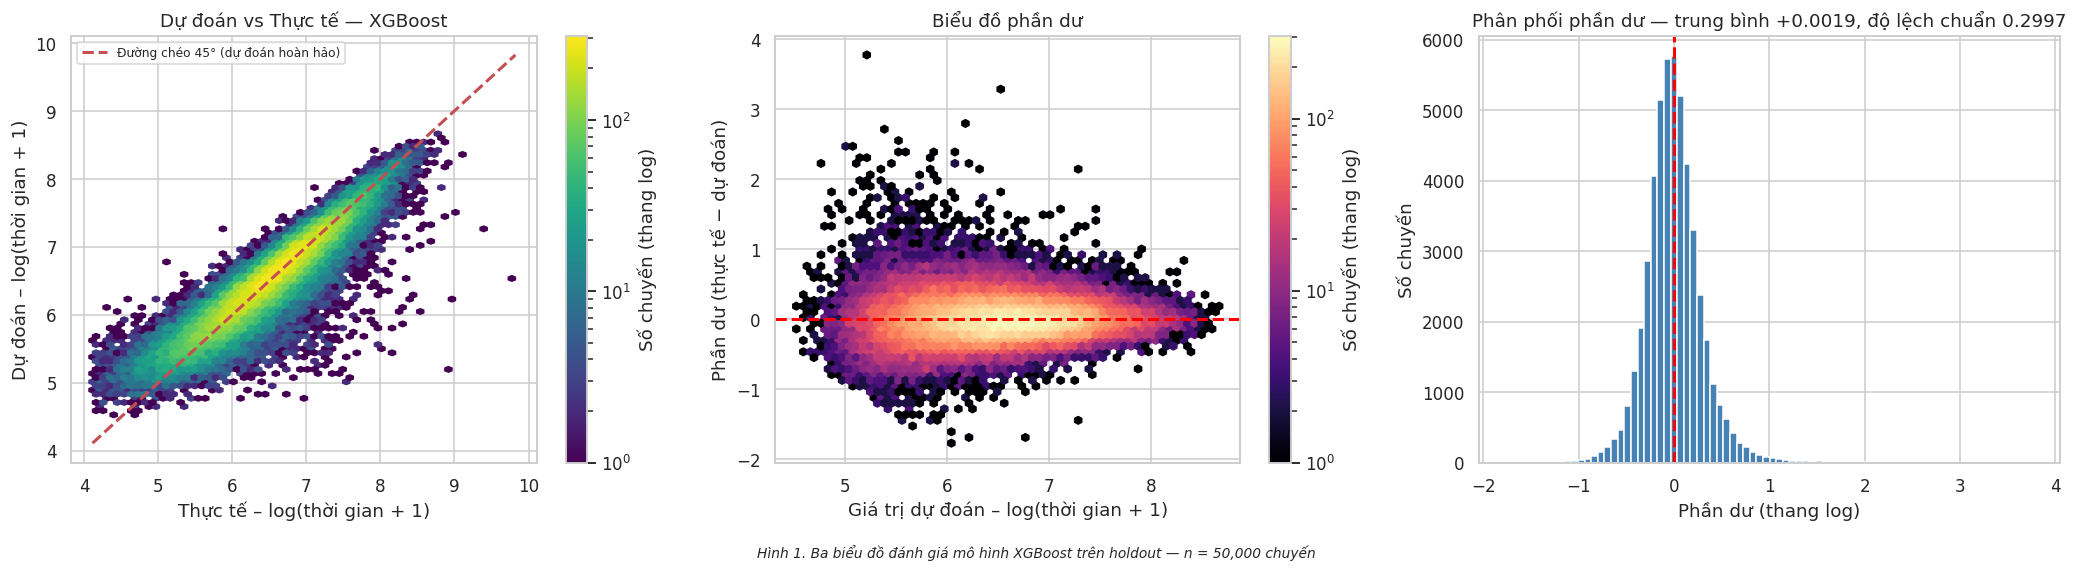

Phần dư: trung bình +0.0019 (gần 0 ⇒ không lệch hệ thống) | độ lệch chuẩn 0.2997
Tỉ lệ dự đoán THIẾU (dự đoán < thực tế): 47.4%


In [16]:
mau = np.random.RandomState(SEED).choice(len(y_hold), min(50_000, len(y_hold)), replace=False)
yt_log, yp_log = np.asarray(y_hold)[mau], PRED_LOG[mau]
phan_du = yt_log - yp_log

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

# (1) Dự đoán vs Thực tế
hb = axes[0].hexbin(yt_log, yp_log, gridsize=60, cmap='viridis', mincnt=1, bins='log')
lims = [yt_log.min(), yt_log.max()]
axes[0].plot(lims, lims, 'r--', lw=2, label='Đường chéo 45° (dự đoán hoàn hảo)')
axes[0].set_xlabel('Thực tế – log(thời gian + 1)'); axes[0].set_ylabel('Dự đoán – log(thời gian + 1)')
axes[0].set_title(f'Dự đoán vs Thực tế — {BEST_NAME}'); axes[0].legend(fontsize=8)
plt.colorbar(hb, ax=axes[0], label='Số chuyến (thang log)')

# (2) Phần dư vs giá trị dự đoán
hb2 = axes[1].hexbin(yp_log, phan_du, gridsize=60, cmap='magma', mincnt=1, bins='log')
axes[1].axhline(0, color='red', ls='--', lw=2)
axes[1].set_xlabel('Giá trị dự đoán – log(thời gian + 1)'); axes[1].set_ylabel('Phần dư (thực tế − dự đoán)')
axes[1].set_title('Biểu đồ phần dư')
plt.colorbar(hb2, ax=axes[1], label='Số chuyến (thang log)')

# (3) Histogram phần dư
axes[2].hist(phan_du, bins=80, color='steelblue', edgecolor='white')
axes[2].axvline(0, color='red', ls='--', lw=2)
axes[2].set_xlabel('Phần dư (thang log)'); axes[2].set_ylabel('Số chuyến')
axes[2].set_title(f'Phân phối phần dư — trung bình {phan_du.mean():+.4f}, độ lệch chuẩn {phan_du.std():.4f}')

plt.tight_layout()
plt.figtext(0.5, -0.03, f'Hình 1. Ba biểu đồ đánh giá mô hình {BEST_NAME} trên holdout — n = {len(mau):,} chuyến',
            ha='center', fontsize=9, style='italic')
plt.savefig('figures/danh_gia_mo_hinh.png', dpi=120, bbox_inches='tight')
plt.show()

print(f'Phần dư: trung bình {phan_du.mean():+.4f} (gần 0 ⇒ không lệch hệ thống) | '
      f'độ lệch chuẩn {phan_du.std():.4f}')
print(f'Tỉ lệ dự đoán THIẾU (dự đoán < thực tế): {(phan_du > 0).mean():.1%}')

## Cell 14 – Giải thích mô hình (1): hệ số của mô hình tuyến tính
Vì đặc trưng số đã được `StandardScaler` chuẩn hoá, **độ lớn hệ số so sánh được với nhau**: hệ số dương nghĩa là đặc trưng tăng thì thời gian chuyến đi tăng.

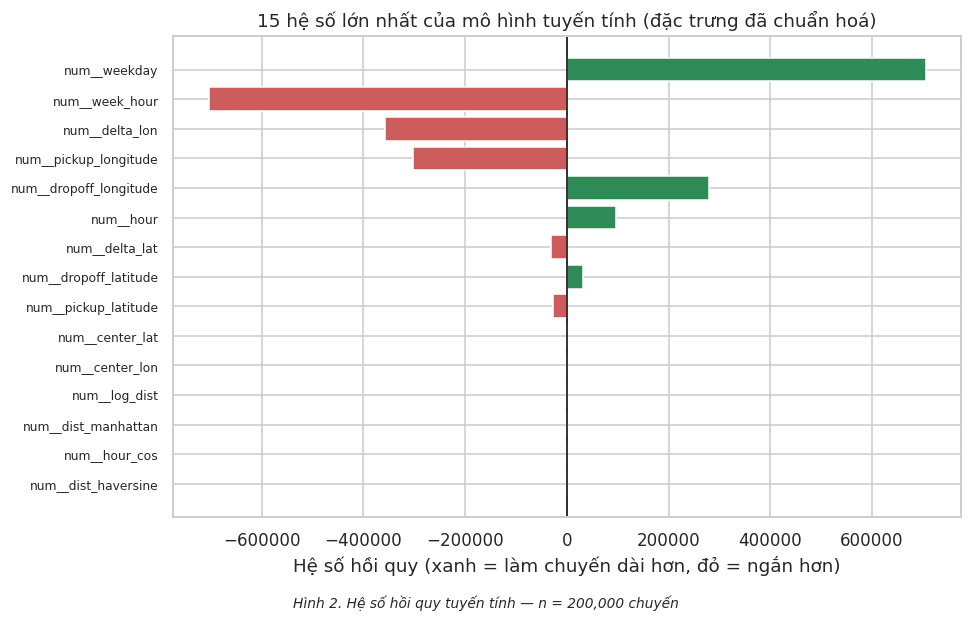

,hệ số
num__weekday,704929.1243
num__week_hour,-703403.4873
num__delta_lon,-356926.5743
num__pickup_longitude,-301650.1523
num__dropoff_longitude,278485.1816
num__hour,96289.7267
num__delta_lat,-32120.6116
num__dropoff_latitude,31732.5715
num__pickup_latitude,-27754.2885
num__center_lat,-15.4572


In [17]:
lin_fit = Pipeline([('pre', pre), ('model', LinearRegression())]).fit(X_dev, y_dev)
ten_cot = lin_fit.named_steps['pre'].get_feature_names_out()
he_so = pd.Series(np.ravel(lin_fit.named_steps['model'].coef_), index=ten_cot)
top_hs = he_so.reindex(he_so.abs().sort_values(ascending=False).index).head(15)

fig, ax = plt.subplots(figsize=(9, 5.5))
mau_sac = ['seagreen' if v > 0 else 'indianred' for v in top_hs]
ax.barh(range(len(top_hs)), top_hs.values, color=mau_sac)
ax.set_yticks(range(len(top_hs))); ax.set_yticklabels(top_hs.index, fontsize=8)
ax.axvline(0, color='black', lw=1); ax.invert_yaxis()
ax.set_xlabel('Hệ số hồi quy (xanh = làm chuyến dài hơn, đỏ = ngắn hơn)')
ax.set_title('15 hệ số lớn nhất của mô hình tuyến tính (đặc trưng đã chuẩn hoá)')
plt.tight_layout()
plt.figtext(0.5, -0.02, f'Hình 2. Hệ số hồi quy tuyến tính — n = {len(X_dev):,} chuyến',
            ha='center', fontsize=9, style='italic')
plt.savefig('figures/he_so_tuyen_tinh.png', dpi=120, bbox_inches='tight')
plt.show()
display(top_hs.round(4).to_frame('hệ số'))

## Cell 15 – Giải thích mô hình (2): Permutation importance
Xáo trộn ngẫu nhiên một cột trên holdout rồi đo RMSLE **tăng** bao nhiêu. Tăng càng nhiều ⇒ cột càng quan trọng. Cách này tin cậy hơn importance nội bộ của mô hình cây vì đo trực tiếp trên dữ liệu chưa từng thấy, và tính theo **cột gốc** nên dễ diễn giải.

Tính xong trong 12s


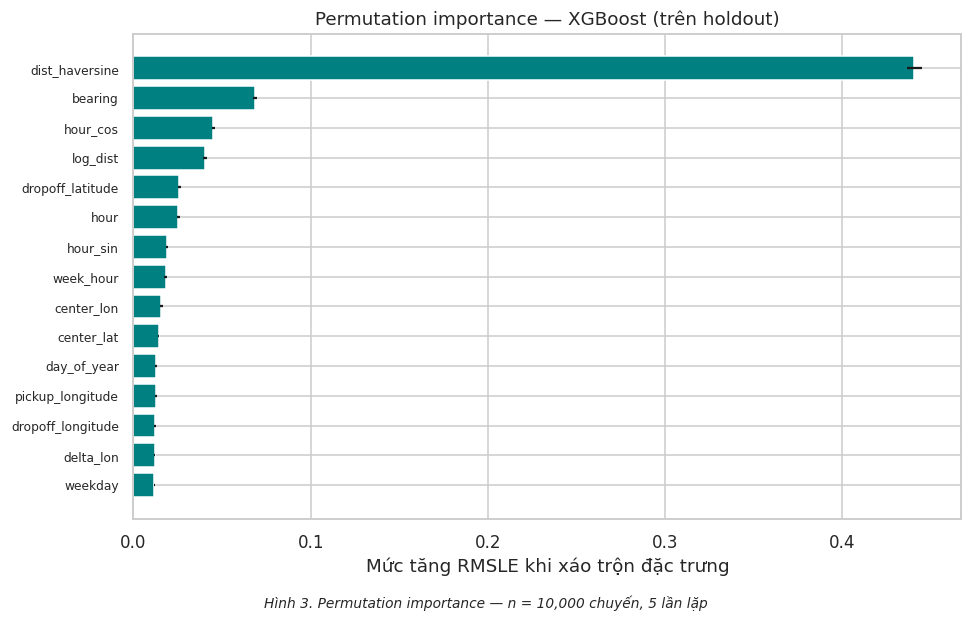

,mean,std
dist_haversine,0.44058,0.00425
bearing,0.06864,0.00105
hour_cos,0.04515,0.00077
log_dist,0.04042,0.00130
dropoff_latitude,0.02600,0.00064
hour,0.02541,0.00071
hour_sin,0.01875,0.00052
week_hour,0.01820,0.00100
center_lon,0.01576,0.00079
center_lat,0.01422,0.00035


In [18]:
idx_pi = np.random.RandomState(SEED).choice(len(X_hold), min(10_000, len(X_hold)), replace=False)
t0 = time.time()
pi = permutation_importance(FINAL_MODEL, X_hold.iloc[idx_pi], y_hold.iloc[idx_pi],
                            n_repeats=5, random_state=SEED, scoring=SCORING[MAIN], n_jobs=1)
imp = pd.DataFrame({'mean': pi.importances_mean, 'std': pi.importances_std},
                   index=X_hold.columns).sort_values('mean', ascending=False)
print(f'Tính xong trong {time.time() - t0:,.0f}s')

top_imp = imp.head(15)
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(range(len(top_imp)), top_imp['mean'], xerr=top_imp['std'], color='teal')
ax.set_yticks(range(len(top_imp))); ax.set_yticklabels(top_imp.index, fontsize=8)
ax.invert_yaxis(); ax.set_xlabel('Mức tăng RMSLE khi xáo trộn đặc trưng')
ax.set_title(f'Permutation importance — {BEST_NAME} (trên holdout)')
plt.tight_layout()
plt.figtext(0.5, -0.02, f'Hình 3. Permutation importance — n = {len(idx_pi):,} chuyến, 5 lần lặp',
            ha='center', fontsize=9, style='italic')
plt.savefig('figures/permutation_importance.png', dpi=120, bbox_inches='tight')
plt.show()
display(imp.head(10).round(5))

## Cell 16 – Giải thích mô hình (3): SHAP
SHAP cho biết mỗi đặc trưng đẩy dự đoán **lên hay xuống** trong **từng chuyến cụ thể**. Chấm đỏ là giá trị đặc trưng cao, chấm xanh là thấp; nằm bên phải nghĩa là làm tăng thời gian dự đoán.
Chỉ áp dụng cho mô hình cây; nếu mô hình thắng cuộc là tuyến tính hoặc MLP, cell tự bỏ qua và dùng kết quả ở Cell 14–15.

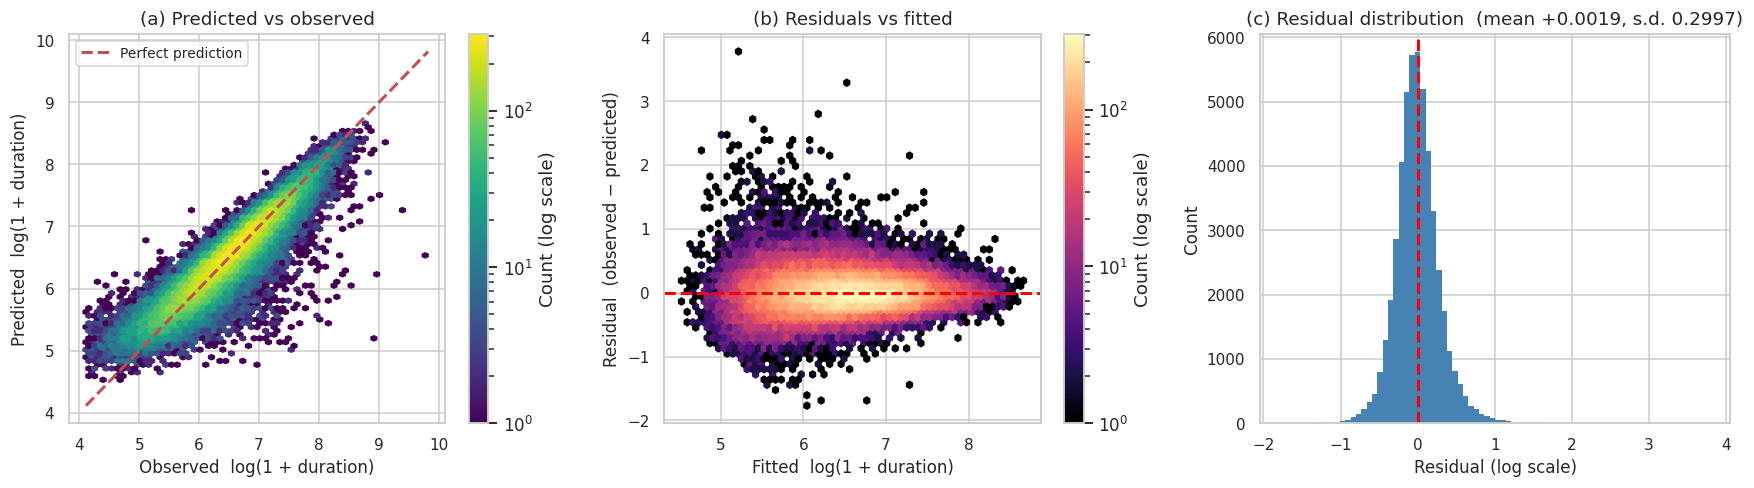

Residual mean +0.0019 | s.d. 0.2997
Under-predictions: 47.4%


In [19]:
mau = np.random.RandomState(SEED).choice(len(y_hold), min(50_000, len(y_hold)), replace=False)
yt_log, yp_log = np.asarray(y_hold)[mau], PRED_LOG[mau]
phan_du = yt_log - yp_log

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))

# (a) Predicted vs observed
hb = axes[0].hexbin(yt_log, yp_log, gridsize=60, cmap='viridis', mincnt=1, bins='log')
lims = [yt_log.min(), yt_log.max()]
axes[0].plot(lims, lims, 'r--', lw=2, label='Perfect prediction')
axes[0].set_xlabel('Observed  log(1 + duration)', fontsize=11)
axes[0].set_ylabel('Predicted  log(1 + duration)', fontsize=11)
axes[0].set_title('(a) Predicted vs observed', fontsize=12)
axes[0].legend(fontsize=9)
plt.colorbar(hb, ax=axes[0], label='Count (log scale)')

# (b) Residuals vs fitted
hb2 = axes[1].hexbin(yp_log, phan_du, gridsize=60, cmap='magma', mincnt=1, bins='log')
axes[1].axhline(0, color='red', ls='--', lw=2)
axes[1].set_xlabel('Fitted  log(1 + duration)', fontsize=11)
axes[1].set_ylabel('Residual  (observed − predicted)', fontsize=11)
axes[1].set_title('(b) Residuals vs fitted', fontsize=12)
plt.colorbar(hb2, ax=axes[1], label='Count (log scale)')

# (c) Residual distribution
axes[2].hist(phan_du, bins=80, color='steelblue', edgecolor='none')
axes[2].axvline(0, color='red', ls='--', lw=2)
axes[2].set_xlabel('Residual (log scale)', fontsize=11)
axes[2].set_ylabel('Count', fontsize=11)
axes[2].set_title(f'(c) Residual distribution  '
                  f'(mean {phan_du.mean():+.4f}, s.d. {phan_du.std():.4f})', fontsize=12)

for ax in axes:
    ax.tick_params(labelsize=10)

plt.tight_layout()
# KHÔNG có plt.figtext ở đây — caption do LaTeX lo.
plt.savefig('figures/danh_gia_mo_hinh.png', dpi=200, bbox_inches='tight')
plt.show()

print(f'Residual mean {phan_du.mean():+.4f} | s.d. {phan_du.std():.4f}')
print(f'Under-predictions: {(phan_du > 0).mean():.1%}')

## Cell 17 – Phân tích sai số theo nhóm
Nhóm có sai số cao bất thường là nguồn tự nhiên cho phần **giới hạn** và cho hướng mở rộng.

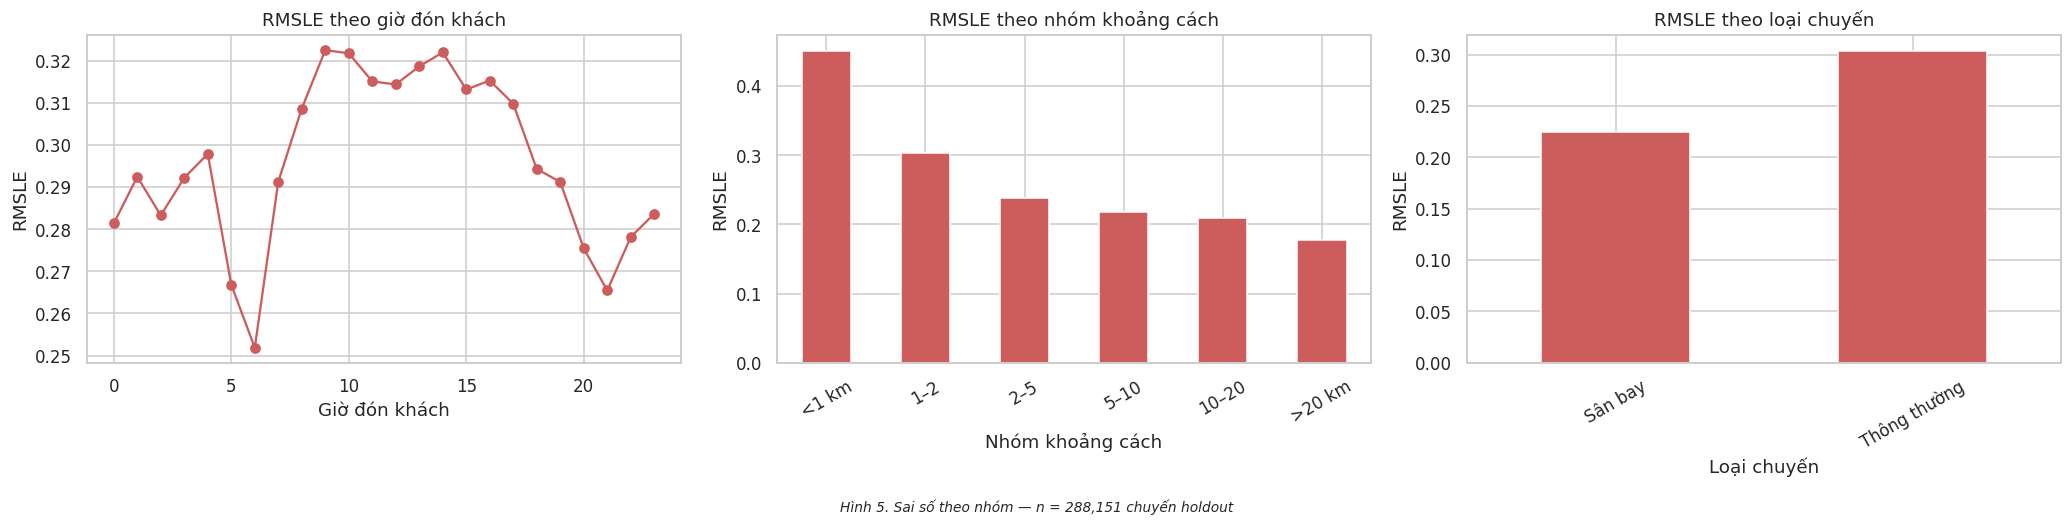

,so_chuyen,MAE_giay,RMSLE
khoang_cach,,,
<1 km,46305,111.917,0.451
1–2,90493,124.840,0.303
2–5,99242,161.914,0.239
5–10,34506,239.071,0.218
10–20,12941,331.146,0.210
>20 km,4664,393.996,0.178


Phân vị của sai số tuyệt đối (giây):
count    288151.0
mean        162.8
std         237.3
min           0.0
50%         102.0
75%         198.7
90%         354.1
95%         506.4
99%        1003.2
max       19270.1


In [20]:
loi = pd.DataFrame({
    'thuc_te_giay': THUC_TE_GIAY,
    'du_doan_giay': PRED_GIAY,
    'phan_du_log': np.asarray(y_hold) - PRED_LOG,
}, index=X_hold.index)
loi['sai_so_tuyet_doi'] = (loi.thuc_te_giay - loi.du_doan_giay).abs()
loi['sai_so_binh_phuong_log'] = loi.phan_du_log ** 2
loi['gio'] = X_hold['hour'].values
loi['khoang_cach'] = pd.cut(X_hold['dist_haversine'].values, [0, 1, 2, 5, 10, 20, 100],
                            labels=['<1 km', '1–2', '2–5', '5–10', '10–20', '>20 km'])
loi['chuyen_san_bay'] = np.where(X_hold['is_airport_trip'].values == 1, 'Sân bay', 'Thông thường')

fig, axes = plt.subplots(1, 3, figsize=(19, 4.6))
for ax, cot, nhan in zip(axes, ['gio', 'khoang_cach', 'chuyen_san_bay'],
                         ['Giờ đón khách', 'Nhóm khoảng cách', 'Loại chuyến']):
    g = loi.groupby(cot, observed=True)['sai_so_binh_phuong_log'].mean() ** 0.5
    if cot == 'gio':
        g.plot(kind='line', ax=ax, marker='o', color='indianred')
    else:
        g.plot(kind='bar', ax=ax, color='indianred')
    ax.set_title(f'RMSLE theo {nhan.lower()}'); ax.set_xlabel(nhan); ax.set_ylabel('RMSLE')
    ax.tick_params(axis='x', rotation=0 if cot == 'gio' else 30)
plt.tight_layout()
plt.figtext(0.5, -0.03, f'Hình 5. Sai số theo nhóm — n = {len(loi):,} chuyến holdout',
            ha='center', fontsize=9, style='italic')
plt.savefig('figures/sai_so_theo_nhom.png', dpi=120, bbox_inches='tight')
plt.show()

bang_loi = (loi.groupby('khoang_cach', observed=True)
              .agg(so_chuyen=('sai_so_tuyet_doi', 'size'),
                   MAE_giay=('sai_so_tuyet_doi', 'mean'),
                   RMSLE=('sai_so_binh_phuong_log', lambda s: s.mean() ** 0.5))
              .sort_values('RMSLE', ascending=False))
display(bang_loi.round(3))
print('Phân vị của sai số tuyệt đối (giây):')
print(loi.sai_so_tuyet_doi.describe(percentiles=[.5, .75, .9, .95, .99]).round(1).to_string())

## Cell 18 – Lưu mô hình và metadata cho dashboard
Lưu **cả Pipeline** (tiền xử lý + mô hình) để dashboard chỉ cần nạp một file. `model_meta.json` ghi phiên bản thư viện, metric và phạm vi dữ liệu train — dashboard dùng để cảnh báo khi người dùng nhập giá trị ngoài phạm vi.

In [21]:
# =============================================================================
#  A.  THAY TOÀN BỘ CELL 41  (cell code nằm ngay dưới markdown
#      "## Cell 18 – Lưu mô hình và metadata cho dashboard")
#
#      Cell 41 hiện đang là bản sao của cell 35 (permutation importance).
#      Xoá sạch nội dung cũ của nó, dán đoạn dưới đây vào.
#      Permutation importance vẫn giữ nguyên ở cell 35, không mất gì.
# =============================================================================
 
import os, json, joblib, numpy as np, pandas as pd
import sklearn
 
os.makedirs('models', exist_ok=True)
# cv_table do Phần 4 sinh ra, ghi lại ở đây để models/ đủ 5 file theo Mục 14
cv_table.to_csv('models/cv_results.csv', index=False, encoding='utf-8-sig')
 
# --- 1. Lưu Pipeline hoàn chỉnh (tiền xử lý + mô hình) --------------------
joblib.dump(FINAL_MODEL, 'models/best_model.joblib')
print('✓ models/best_model.joblib')
 
# --- 2. Metadata ----------------------------------------------------------
X_REF = X_dev_full if 'X_dev_full' in globals() else X_dev
num_cols = [c for c in X_REF.columns if pd.api.types.is_numeric_dtype(X_REF[c])]
 
hang = test_table.set_index('mo_hinh')
ten_hang = (f'{BEST_NAME} – train toàn bộ dev'
            if f'{BEST_NAME} – train toàn bộ dev' in hang.index else BEST_NAME)
metrics_test = {k: float(v) for k, v in hang.loc[ten_hang].items()
                if isinstance(v, (int, float, np.number)) and not isinstance(v, bool)}
print(f'✓ metrics lấy từ dòng "{ten_hang}" của test_table')
 
meta = {
    'model': BEST_NAME,
    'task': 'regression',
    'target': 'trip_duration',
 
    # --- BA KHOÁ BẮT BUỘC -------------------------------------------------
    # Mô hình học trên log1p(trip_duration). Dashboard PHẢI expm1 trước khi
    # hiển thị, nếu không mọi con số sẽ sai hoàn toàn.
    'target_transform': 'log1p',
    'target_inverse': 'expm1',
    'target_unit_after_inverse': 'giây',
    # ----------------------------------------------------------------------
 
    'features': list(X_REF.columns),
    'n_features': int(X_REF.shape[1]),
    'n_train_rows': int(X_REF.shape[0]),
    'n_holdout_rows': int(len(X_hold)),
    'sample_mode': MODE,
    'sample_size': SAMPLE_SIZE,
    'metrics_test': metrics_test,
    'threshold': None,
    'train_range': {c: [float(X_REF[c].min()), float(X_REF[c].max())]
                    for c in num_cols},
    'versions': {'sklearn': sklearn.__version__,
                 'pandas': pd.__version__, 'numpy': np.__version__},
}
try:
    import xgboost
    meta['versions']['xgboost'] = xgboost.__version__
except ImportError:
    pass
 
json.dump(meta, open('models/model_meta.json', 'w', encoding='utf-8'),
          ensure_ascii=False, indent=2)
print('✓ models/model_meta.json')
 
# --- 3. Nạp lại phải cho đúng kết quả cũ ----------------------------------
nap_lai = joblib.load('models/best_model.joblib')
assert np.allclose(nap_lai.predict(X_hold[:5]), FINAL_MODEL.predict(X_hold[:5]))
print('✓ nạp lại khớp dự đoán gốc')
 
# --- 4. Đối chiếu checklist Hướng dẫn 4, Mục 14 ---------------------------
print('\n--- models/ ---')
for f in sorted(os.listdir('models')):
    print(f'   {f:34s} {os.path.getsize("models/" + f):>10,d} bytes')
 
bat_buoc = ['best_model.joblib', 'model_meta.json',
            'cv_results.csv', 'tuning_log.csv', 'test_results.csv']
thieu = [f for f in bat_buoc if not os.path.exists('models/' + f)]
print('\nChecklist Hướng dẫn 4 Mục 14:',
      'ĐỦ' if not thieu else f'CÒN THIẾU {thieu}')
 
m = json.load(open('models/model_meta.json', encoding='utf-8'))
ba = ['target_transform', 'target_inverse', 'target_unit_after_inverse']
print('Ba khoá biến đổi mục tiêu:',
      'ĐỦ' if all(k in m for k in ba) else 'THIẾU',
      {k: m.get(k) for k in ba})
print(f'Mô hình lưu: {m["model"]} | {m["n_features"]} đặc trưng'
      f' | train trên {m["n_train_rows"]:,} dòng')
 
 
# 

✓ models/best_model.joblib
✓ metrics lấy từ dòng "XGBoost – train toàn bộ dev" của test_table
✓ models/model_meta.json
✓ nạp lại khớp dự đoán gốc

--- models/ ---
   baseline_comparison.csv                   862 bytes
   best_model.joblib                   7,445,075 bytes
   cv_results.csv                          1,981 bytes
   model_meta.json                         3,127 bytes
   test_results.csv                        1,014 bytes
   tuning_log.csv                            502 bytes

Checklist Hướng dẫn 4 Mục 14: ĐỦ
Ba khoá biến đổi mục tiêu: ĐỦ {'target_transform': 'log1p', 'target_inverse': 'expm1', 'target_unit_after_inverse': 'giây'}
Mô hình lưu: XGBoost | 30 đặc trưng | train trên 1,152,600 dòng


## Cell 19 – Kết luận

In [22]:
print('=' * 82)
print(f'MÔ HÌNH CUỐI: {BEST_NAME}' + (' (train trên toàn bộ development set)' if FINAL_FULL_FIT else ''))
print('=' * 82)
print(f'  CV RMSLE (mẫu {len(X_dev):,} dòng) : {diem_cv[BEST_NAME]:.4f}')
print(f'  Holdout RMSLE (thang log)      : {rmsle(y_hold, PRED_LOG):.4f}')
print(f'  Holdout MAE                    : {mae_seconds(y_hold, PRED_LOG):,.1f} giây '
      f'(≈ {mae_seconds(y_hold, PRED_LOG)/60:.1f} phút)')
print(f'  Holdout RMSE                   : {rmse_seconds(y_hold, PRED_LOG):,.1f} giây')
print(f'  Holdout R² (thang log)         : {r2_score(y_hold, PRED_LOG):.4f}')
print(f'  Cải thiện so với Linear        : {(lin_cv - diem_cv[BEST_NAME]) / lin_cv:.1%} RMSLE')
print(f'\n  Tỉ lệ RMSE/MAE = {rmse_seconds(y_hold, PRED_LOG) / mae_seconds(y_hold, PRED_LOG):.2f} '
      f'(càng lớn ⇒ sai số càng tập trung ở một nhóm nhỏ chuyến bị lệch nặng)')
print(f'\n  Ba đặc trưng quan trọng nhất   : {", ".join(imp.head(3).index)}')

MÔ HÌNH CUỐI: XGBoost (train trên toàn bộ development set)
  CV RMSLE (mẫu 200,000 dòng) : 0.3071
  Holdout RMSLE (thang log)      : 0.2990
  Holdout MAE                    : 162.8 giây (≈ 2.7 phút)
  Holdout RMSE                   : 287.8 giây
  Holdout R² (thang log)         : 0.8305
  Cải thiện so với Linear        : 23.9% RMSLE

  Tỉ lệ RMSE/MAE = 1.77 (càng lớn ⇒ sai số càng tập trung ở một nhóm nhỏ chuyến bị lệch nặng)

  Ba đặc trưng quan trọng nhất   : dist_haversine, bearing, hour_cos


### Giới hạn (ghi vào báo cáo)
1. **Tinh chỉnh trên mẫu con.** `RandomizedSearchCV` chạy trên mẫu nhỏ hơn rồi mới xác nhận bằng 5-fold CV trên mẫu 300k, do giới hạn thời gian của Kaggle. Tham số tối ưu trên toàn bộ dữ liệu có thể khác.
2. **Số tổ hợp tham số còn ít.** Với nhiều vòng tìm kiếm hơn (hoặc dùng Optuna) kết quả có thể tốt hơn.
3. **Holdout đã qua cleaning** nên "dễ" hơn tập test thật của cuộc thi ⇒ không so trực tiếp với leaderboard.
4. **Chưa dùng PCA/K-Means và dữ liệu ngoài** (lộ trình OSRM, thời tiết) mà các nghiên cứu công bố có dùng.
5. **Sai số còn lại phần lớn không dự đoán được**: dữ liệu không chứa thông tin về tắc đường thời gian thực, tai nạn hay tuyến đường tài xế chọn. Hai chuyến giống nhau ở mọi đặc trưng vẫn có thể chênh nhau vài phút.
6. **Nhóm chuyến có sai số cao** (xem Cell 17) là hướng cải thiện tự nhiên cho vòng sau.

### Đã hoàn thành tiêu chí 7 (Definition of Done)
- [x] Năm mô hình dùng chung đặc trưng, cách chia và `cv` — Phần 4
- [x] Cross-validation 5 fold — Phần 4 và Cell 9
- [x] So với baseline nội bộ (Linear) và baseline bài báo — Cell 12
- [x] **Log tinh chỉnh** `models/tuning_log.csv` ghi cấu hình và điểm CV trước/sau — Cell 9
- [x] **In đậm mô hình tốt nhất** trong bảng kết quả — Cell 10
- [x] Giải thích mô hình (hệ số, permutation importance, SHAP) và phân tích sai số — Cell 14–17
- [x] Lưu mô hình + metadata, kiểm tra nạp lại — Cell 18
- [ ] Chạy `Restart and run all` một lần trước khi nộp

### Bước tiếp theo
Hướng dẫn 5 — Dashboard và Analysis tool: nạp `models/best_model.joblib`, hiển thị dự đoán kèm khoảng sai số (dùng `MAE_seconds` trong `model_meta.json`) và cảnh báo khi người dùng nhập giá trị ngoài `train_range`.

In [23]:
# ===== XUẤT SỐ LIỆU CHO BÁO CÁO =====
import io, sys
import numpy as np
buf = io.StringIO()
def P(*a): print(*a); print(*a, file=buf)
co = lambda t: t in globals()

P('[1] CAU HINH & KICH THUOC')
for t in ['MODE', 'SAMPLE_SIZE']:
    if co(t): P(f'  {t} = {globals()[t]}')
if co('raw'):    P(f'  So dong goc              : {len(raw):,}')
if co('n_thua'): P(f'  Ban sao trung lap da loai: {n_thua:,}')
if co('df'):     P(f'  Sau cleaning             : {len(df):,}')
if co('raw') and co('df'): P(f'  Ti le bi loai            : {1-len(df)/len(raw):.4%}')
for t, n in [('X_dev_full','Development (toan bo)'), ('X_dev','Mau so sanh'), ('X_hold','Holdout')]:
    if co(t): P(f'  {n:<25}: {len(globals()[t]):,}')
if co('FEATURES'): P(f'  So dac trung             : {len(FEATURES)}')

P('\n[2] PERMUTATION IMPORTANCE (top 12)')
P(imp.head(12).round(5).to_string() if co('imp') else '  (chua co)')

P('\n[3] SAI SO THEO NHOM')
if co('loi'):
    for cot in ['gio', 'khoang_cach', 'chuyen_san_bay']:
        if cot in loi.columns:
            g = loi.groupby(cot, observed=True).agg(
                n=('sai_so_tuyet_doi','size'), MAE_giay=('sai_so_tuyet_doi','mean'),
                RMSLE=('sai_so_binh_phuong_log', lambda s: s.mean()**0.5))
            P(f'\n  --- theo {cot} ---'); P(g.round(3).to_string())
    P('\n  --- phan vi sai so tuyet doi (giay) ---')
    P(loi.sai_so_tuyet_doi.describe(percentiles=[.5,.75,.9,.95,.99]).round(1).to_string())
else: P('  (chua co)')

P('\n[4] PHAN DU')
if co('PRED_LOG') and co('y_hold'):
    r = np.asarray(y_hold) - PRED_LOG
    P(f'  trung binh = {r.mean():+.5f} | do lech chuan = {r.std():.5f}')
    P(f'  ti le du doan THIEU = {(r > 0).mean():.2%}')

P('\n[5] PHIEN BAN')
import sklearn, xgboost, pandas
P(f'  sklearn {sklearn.__version__} | xgboost {xgboost.__version__} | '
  f'pandas {pandas.__version__} | numpy {np.__version__}')

open('bao_cao_so_lieu.txt','w',encoding='utf-8').write(buf.getvalue())
print('\n>>> Da luu bao_cao_so_lieu.txt')

[1] CAU HINH & KICH THUOC
  MODE = fast
  SAMPLE_SIZE = 200000
  So dong goc              : 1,458,644
  Ban sao trung lap da loai: 7
  Sau cleaning             : 1,440,751
  Ti le bi loai            : 1.2267%
  Development (toan bo)    : 1,152,600
  Mau so sanh              : 200,000
  Holdout                  : 288,151
  So dac trung             : 30

[2] PERMUTATION IMPORTANCE (top 12)
                     mean      std
dist_haversine    0.44058  0.00425
bearing           0.06864  0.00105
hour_cos          0.04515  0.00077
log_dist          0.04042  0.00130
dropoff_latitude  0.02600  0.00064
hour              0.02541  0.00071
hour_sin          0.01875  0.00052
week_hour         0.01820  0.00100
center_lon        0.01576  0.00079
center_lat        0.01422  0.00035
day_of_year       0.01284  0.00063
pickup_longitude  0.01271  0.00053

[3] SAI SO THEO NHOM

  --- theo gio ---
          n  MAE_giay  RMSLE
gio                         
0.0   10470   144.563  0.281
1.0    7614   138.011  0.

In [24]:
ss = loi['sai_so_tuyet_doi']

print('\n\n=== SAI SỐ TUYỆT ĐỐI TRÊN HOLDOUT ===')
print(f'  Trung vị    : {ss.median():,.0f} giây')
print(f'  Phân vị 75  : {ss.quantile(0.75):,.0f} giây')
print(f'  Phân vị 99  : {ss.quantile(0.99):,.0f} giây')
print(f'  Lớn nhất    : {ss.max():,.0f} giây  =  {ss.max()/3600:.1f} giờ')

print('\n>>> GỬI MÌNH DÒNG NÀY:')
print(f'    MaxAbsError = {ss.max():,.0f} giay = {ss.max()/3600:.1f} gio')

# Bài báo đang ghi sẵn: trung vị 102 s, phân vị 75 là 199 s, phân vị 99 là 1003 s.
# Nếu ba con số trên lệch với bài thì gửi hết, mình sửa luôn cả đoạn.

print('\n--- Đối chiếu với con số đang ghi trong bài ---')
for nhan, trong_bai, thuc_te in [
    ('Trung vị',   102,  ss.median()),
    ('Phân vị 75', 199,  ss.quantile(0.75)),
    ('Phân vị 99', 1003, ss.quantile(0.99)),
]:
    dau = 'KHỚP' if abs(trong_bai - thuc_te) < 1 else '>>> LỆCH <<<'
    print(f'  {nhan:<12} bài ghi {trong_bai:>6,}  |  thực tế {thuc_te:>8,.0f}  →  {dau}')




=== SAI SỐ TUYỆT ĐỐI TRÊN HOLDOUT ===
  Trung vị    : 102 giây
  Phân vị 75  : 199 giây
  Phân vị 99  : 1,003 giây
  Lớn nhất    : 19,270 giây  =  5.4 giờ

>>> GỬI MÌNH DÒNG NÀY:
    MaxAbsError = 19,270 giay = 5.4 gio

--- Đối chiếu với con số đang ghi trong bài ---
  Trung vị     bài ghi    102  |  thực tế      102  →  KHỚP
  Phân vị 75   bài ghi    199  |  thực tế      199  →  KHỚP
  Phân vị 99   bài ghi  1,003  |  thực tế    1,003  →  KHỚP


In [25]:
# =============================================================================
#  LẤP ĐẦY BẢNG LỖI THEO PHÂN KHÚC  (Bảng 8 trong bài, tab:segments)
#
#  ĐẶT Ở ĐÂU: cuối notebook PHẦN 5, sau cell tạo bảng `loi`.
#             (Ctrl+F tìm "sai_so_tuyet_doi" để biết cell đó ở đâu.)
#
#  Script in ra NGUYÊN PHẦN THÂN BẢNG LaTeX — copy rồi dán đè vào main.tex,
#  không phải chép tay từng số.
# =============================================================================

import numpy as np
import pandas as pd


def rmsle_tu_log(nhom):
    """RMSLE = căn bậc hai của trung bình bình phương phần dư trên thang log."""
    return float(nhom.mean() ** 0.5)


# --- Theo khoảng cách: đủ cả 6 dải -------------------------------------------
g_dist = loi.groupby('khoang_cach', observed=True).agg(
    mae=('sai_so_tuyet_doi', 'mean'),
    msle=('sai_so_binh_phuong_log', 'mean'),
)
g_dist['rmsle'] = g_dist['msle'] ** 0.5

# --- Theo loại chuyến --------------------------------------------------------
g_type = loi.groupby('chuyen_san_bay', observed=True).agg(
    mae=('sai_so_tuyet_doi', 'mean'),
    msle=('sai_so_binh_phuong_log', 'mean'),
)
g_type['rmsle'] = g_type['msle'] ** 0.5

# --- Theo giờ: lấy giờ tốt nhất và giờ tệ nhất, KÈM MAE ----------------------
g_hour = loi.groupby('gio', observed=True).agg(
    mae=('sai_so_tuyet_doi', 'mean'),
    msle=('sai_so_binh_phuong_log', 'mean'),
)
g_hour['rmsle'] = g_hour['msle'] ** 0.5
gio_tot = g_hour['rmsle'].idxmin()
gio_te = g_hour['rmsle'].idxmax()

print('=== KIỂM TRA NHANH ===')
print(g_dist[['mae', 'rmsle']].round(3).to_string())
print()
print(g_type[['mae', 'rmsle']].round(3).to_string())
print(f'\nGiờ tốt nhất : {int(gio_tot)}:00  (RMSLE {g_hour.loc[gio_tot, "rmsle"]:.3f})')
print(f'Giờ tệ nhất  : {int(gio_te)}:00  (RMSLE {g_hour.loc[gio_te, "rmsle"]:.3f})')

# =============================================================================
#  THÂN BẢNG LaTeX — copy từ dòng BEGIN tới dòng END
# =============================================================================
print('\n\n========== COPY TỪ ĐÂY ==========')

NHAN = {'<1 km': r'$<1$~km', '1–2': r'1--2~km', '2–5': r'2--5~km',
        '5–10': r'5--10~km', '10–20': r'10--20~km', '>20 km': r'$>20$~km'}

print(r'\multicolumn{3}{@{}l}{\emph{By distance}}\\')
for nhan, r in g_dist.iterrows():
    ten = NHAN.get(str(nhan), str(nhan))
    print(f'\\quad {ten:<14} & {r.mae:,.0f} & {r.rmsle:.3f} \\\\')

print(r'\midrule')
print(r'\multicolumn{3}{@{}l}{\emph{By trip type}}\\')
for nhan, r in g_type.iterrows():
    ten = 'Airport' if 'bay' in str(nhan) else 'Non-airport'
    print(f'\\quad {ten:<14} & {r.mae:,.0f} & {r.rmsle:.3f} \\\\')

print(r'\midrule')
print(r'\multicolumn{3}{@{}l}{\emph{By hour of day}}\\')
for nhan, gio in [('best', gio_tot), ('worst', gio_te)]:
    r = g_hour.loc[gio]
    print(f'\\quad {int(gio):02d}:00 ({nhan}){"":<3} & {r.mae:,.0f} & {r.rmsle:.3f} \\\\')

print('========== TỚI ĐÂY ==========')

# --- Đối chiếu với con số đang ghi trong bài ---------------------------------
print('\n--- Đối chiếu với bài ---')
for nhan, trong_bai_mae, trong_bai_rmsle in [('<1 km', 112, 0.451), ('>20 km', 394, 0.178)]:
    if nhan in g_dist.index:
        r = g_dist.loc[nhan]
        ok_mae = abs(r.mae - trong_bai_mae) < 1
        ok_rm = abs(r.rmsle - trong_bai_rmsle) < 0.002
        print(f'  {nhan:<8} MAE bài {trong_bai_mae:>4} / thật {r.mae:>6,.0f}  {"KHỚP" if ok_mae else ">>> LỆCH"}'
              f'   |  RMSLE bài {trong_bai_rmsle} / thật {r.rmsle:.3f}  {"KHỚP" if ok_rm else ">>> LỆCH"}')

=== KIỂM TRA NHANH ===
                 mae  rmsle
khoang_cach                
<1 km        111.917  0.451
1–2          124.840  0.303
2–5          161.914  0.239
5–10         239.071  0.218
10–20        331.146  0.210
>20 km       393.996  0.178

                    mae  rmsle
chuyen_san_bay                
Sân bay         323.531  0.225
Thông thường    151.254  0.304

Giờ tốt nhất : 6:00  (RMSLE 0.252)
Giờ tệ nhất  : 9:00  (RMSLE 0.322)


========== COPY TỪ ĐÂY ==========
\multicolumn{3}{@{}l}{\emph{By distance}}\\
\quad $<1$~km        & 112 & 0.451 \\
\quad 1--2~km        & 125 & 0.303 \\
\quad 2--5~km        & 162 & 0.239 \\
\quad 5--10~km       & 239 & 0.218 \\
\quad 10--20~km      & 331 & 0.210 \\
\quad $>20$~km       & 394 & 0.178 \\
\midrule
\multicolumn{3}{@{}l}{\emph{By trip type}}\\
\quad Airport        & 324 & 0.225 \\
\quad Non-airport    & 151 & 0.304 \\
\midrule
\multicolumn{3}{@{}l}{\emph{By hour of day}}\\
\quad 06:00 (best)    & 107 & 0.252 \\
\quad 09:00 (worst)    &

In [26]:
import os
print(os.getcwd())
for r, d, f in os.walk('/kaggle/working'):
    for x in f:
        p = os.path.join(r, x)
        print(f'{os.path.getsize(p)/1e6:8.2f} MB  {p}')

/kaggle/working
    0.00 MB  /kaggle/working/bao_cao_so_lieu.txt
    1.07 MB  /kaggle/working/__notebook__.ipynb
    0.00 MB  /kaggle/working/models/cv_results.csv
    7.45 MB  /kaggle/working/models/best_model.joblib
    0.00 MB  /kaggle/working/models/test_results.csv
    0.00 MB  /kaggle/working/models/model_meta.json
    0.00 MB  /kaggle/working/models/baseline_comparison.csv
    0.00 MB  /kaggle/working/models/tuning_log.csv
    0.10 MB  /kaggle/working/figures/sai_so_theo_nhom.png
    0.06 MB  /kaggle/working/figures/he_so_tuyen_tinh.png
    0.41 MB  /kaggle/working/figures/danh_gia_mo_hinh.png
    0.05 MB  /kaggle/working/figures/permutation_importance.png


In [27]:
import os, zipfile
from IPython.display import FileLink

with zipfile.ZipFile('ket_qua.zip', 'w', zipfile.ZIP_DEFLATED) as z:
    for folder in ['figures', 'models']:
        if os.path.isdir(folder):
            for root, _, files in os.walk(folder):
                for f in files:
                    p = os.path.join(root, f)
                    z.write(p, p)
                    print('  +', p)

print(f'\nket_qua.zip — {os.path.getsize("ket_qua.zip")/1e6:.2f} MB')
FileLink('ket_qua.zip')

  + figures/sai_so_theo_nhom.png
  + figures/he_so_tuyen_tinh.png
  + figures/danh_gia_mo_hinh.png
  + figures/permutation_importance.png
  + models/cv_results.csv
  + models/best_model.joblib
  + models/test_results.csv
  + models/model_meta.json
  + models/baseline_comparison.csv
  + models/tuning_log.csv

ket_qua.zip — 3.15 MB


/kaggle/working/ket_qua.zip

In [28]:
# =============================================================================
#  C2 — CHẤM MÔ HÌNH TRÊN CÁC DÒNG ĐÃ BỊ LOẠI
#
#  ĐẶT Ở ĐÂU: thêm MỘT cell mới ở CUỐI notebook PHẦN 5.
#             Phải chạy sau khi đã có FINAL_MODEL (tức sau cell 18).
#
#  VÌ SAO: con số 40,4% trong bài gộp hai hiệu ứng mà thí nghiệm Kaggle
#  không tách được —
#      (a) tập holdout đã làm sạch thì dễ chấm hơn,
#      (b) mô hình được huấn luyện trên dữ liệu bị cắt ngưỡng nên có trần.
#
#  Cell này chấm mô hình trên 17.893 dòng ĐÃ BỊ LOẠI khỏi tập huấn luyện.
#  Những dòng đó mô hình chưa bao giờ thấy, VÀ nhóm có nhãn của chúng —
#  khác tập test Kaggle. Chia theo từng luật lọc thì biết luật nào gây ra
#  phần lớn chênh lệch.
#
#  Cell tự nạp lại raw nên không cần chạy gì trước ngoài FINAL_MODEL.
# =============================================================================

import glob
import numpy as np
import pandas as pd

# -----------------------------------------------------------------------------
#  0. KIỂM BIẾN CẦN THIẾT
# -----------------------------------------------------------------------------
thieu = [v for v in ('FINAL_MODEL', 'add_features', 'FEATURES')
         if v not in globals()]
assert not thieu, f'Thiếu {thieu} — chạy cell 18 và các cell trước đó đã.'

# -----------------------------------------------------------------------------
#  1. NẠP LẠI DỮ LIỆU THÔ
# -----------------------------------------------------------------------------
duong_dan = find_file('train')
assert duong_dan, 'Không tìm thấy train — kiểm tra Input của notebook'
raw = pd.read_csv(duong_dan, parse_dates=['pickup_datetime'])
print(f'Nạp: {duong_dan}  ->  {len(raw):,} dòng')
assert len(raw) == 1_458_644, f'Số dòng bất thường: {len(raw):,}'

# -----------------------------------------------------------------------------
#  2. DỰNG LẠI CÁC LUẬT LỌC, ĐÚNG THỨ TỰ BẢNG THÁC NƯỚC TRONG BÀI
# -----------------------------------------------------------------------------
R = 6371.0
d = raw.copy()
p1 = np.radians(d.pickup_latitude.values)
p2 = np.radians(d.dropoff_latitude.values)
dphi = p2 - p1
dlam = np.radians(d.dropoff_longitude.values - d.pickup_longitude.values)
a = np.sin(dphi / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dlam / 2) ** 2
d['_dist'] = 2 * R * np.arcsin(np.sqrt(np.clip(a, 0, 1)))
d['_speed'] = d._dist / (d.trip_duration / 3600.0)

trung = d.drop(columns=['id', '_dist', '_speed']).duplicated()

LUAT = [
    ('Exact duplicates', trung.values),
    ('Duration bounds',  ~d.trip_duration.between(60, 21600).values),
    ('Passenger bounds', ~d.passenger_count.between(1, 6).values),
    ('Latitude bounds',  ~(d.pickup_latitude.between(40.49, 40.92)
                           & d.dropoff_latitude.between(40.49, 40.92)).values),
    ('Longitude bounds', ~(d.pickup_longitude.between(-74.27, -73.68)
                           & d.dropoff_longitude.between(-74.27, -73.68)).values),
    ('Minimum distance', (d._dist < 0.05).values),
    ('Maximum speed',    (d._speed > 100).values),
]

# gán nhãn luật ĐẦU TIÊN loại mỗi dòng — khớp cách đếm của bảng thác nước
nhan = np.full(len(d), None, dtype=object)
for ten, mask in LUAT:
    chua_co = pd.isna(nhan)
    nhan[chua_co & mask] = ten

bi_loai = pd.notna(nhan)
print(f'Tổng dòng bị loại: {bi_loai.sum():,}   (bài ghi 17.893)')
if bi_loai.sum() != 17_893:
    print('  ⚠ lệch so với bài — kiểm lại ngưỡng trước khi dùng kết quả')

# -----------------------------------------------------------------------------
#  3. CHẤM MÔ HÌNH TRÊN CHÍNH NHỮNG DÒNG ĐÓ
# -----------------------------------------------------------------------------
bo = raw[bi_loai].copy()
bo['_luat'] = nhan[bi_loai]

fe = add_features(bo)
thieu_cot = [c for c in FEATURES if c not in fe.columns]
assert not thieu_cot, f'add_features không sinh ra: {thieu_cot}'

X = fe[FEATURES].astype('float32')
y = np.log1p(bo.trip_duration.values.astype('float64'))

hong = ~np.isfinite(X.values).all(axis=1)
if hong.any():
    print(f'  bỏ {hong.sum():,} dòng có đặc trưng không hữu hạn')
    X, y, bo = X[~hong], y[~hong], bo[~hong]

pred = FINAL_MODEL.predict(X)
giay_that = np.expm1(y)
giay_doan = np.clip(np.expm1(pred), 0, None)

# -----------------------------------------------------------------------------
#  4. BÁO CÁO THEO TỪNG LUẬT
# -----------------------------------------------------------------------------
print(f'\n{"Luật loại":<20}{"n":>9}{"RMSLE":>10}{"MAE (s)":>12}'
      f'{"trung vị y":>13}')
print('-' * 64)

hang = []
for ten, _ in LUAT:
    m = (bo._luat == ten).values
    if m.sum() == 0:
        continue
    rr = float(np.sqrt(np.mean((y[m] - pred[m]) ** 2)))
    mm = float(np.mean(np.abs(giay_that[m] - giay_doan[m])))
    tv = float(np.median(giay_that[m]))
    hang.append({'luat': ten, 'n': int(m.sum()), 'rmsle': rr,
                 'mae_giay': mm, 'trung_vi_giay': tv})
    print(f'{ten:<20}{m.sum():>9,}{rr:>10.4f}{mm:>12,.0f}{tv:>13,.0f}')

rr_all = float(np.sqrt(np.mean((y - pred) ** 2)))
mm_all = float(np.mean(np.abs(giay_that - giay_doan)))
print('-' * 64)
print(f'{"TẤT CẢ":<20}{len(y):>9,}{rr_all:>10.4f}{mm_all:>12,.0f}')

pd.DataFrame(hang).to_csv('models/removed_rows_score.csv', index=False,
                          encoding='utf-8-sig')
print('\n→ models/removed_rows_score.csv')

# -----------------------------------------------------------------------------
#  5. ĐỌC KẾT QUẢ
# -----------------------------------------------------------------------------
print('\n=== ĐỐI CHIẾU ===')
print('  Holdout đã làm sạch        : 0,2990')
print('  Kaggle, tập chưa lọc       : 0,4199')
print(f'  Các dòng bị loại           : {rr_all:.4f}')
print()
if hang:
    nang = max(hang, key=lambda h: h['rmsle'])
    print(f'  Luật có RMSLE cao nhất: {nang["luat"]} '
          f'({nang["rmsle"]:.4f} trên {nang["n"]:,} dòng)')
    print()
    if nang['luat'] == 'Duration bounds':
        print('  → Đúng như bài dự đoán. Những chuyến dài bị cắt khỏi tập train')
        print('    chính là nhóm mô hình sai nặng nhất. Đây là bằng chứng TRỰC TIẾP')
        print('    cho cơ chế "trần 5.672 giây", mạnh hơn lập luận hiện tại trong')
        print('    bài vốn chỉ suy ra từ giá trị lớn nhất của dự đoán.')
    else:
        print('  → KHÁC với dự đoán trong bài. Cơ chế gây ra 40,4% có thể không')
        print('    chủ yếu là luật giới hạn thời lượng. Phải viết lại Mục VI-B.')

print('\nGỬI MÌNH NGUYÊN PHẦN IN RA TỪ DÒNG "Tổng dòng bị loại" TRỞ XUỐNG.')

Nạp: /kaggle/input/competitions/nyc-taxi-trip-duration/train.zip  ->  1,458,644 dòng
Tổng dòng bị loại: 17,893   (bài ghi 17.893)

Luật loại                   n     RMSLE     MAE (s)   trung vị y
----------------------------------------------------------------
Exact duplicates            7    2.5145      12,600          379
Duration bounds        10,654    3.2799      16,936           34
Passenger bounds           19    0.8490         332          560
Latitude bounds           556    0.5899         690        2,362
Longitude bounds          488    0.4525         560        2,264
Minimum distance        6,136    1.0076         455          506
Maximum speed              33    1.9264       1,653          267
----------------------------------------------------------------
TẤT CẢ                 17,893    2.6038      10,285

→ models/removed_rows_score.csv

=== ĐỐI CHIẾU ===
  Holdout đã làm sạch        : 0,2990
  Kaggle, tập chưa lọc       : 0,4199
  Các dòng bị loại           : 2.6038



In [29]:
# =============================================================================
#  C2b — TÁCH LUẬT THỜI LƯỢNG THÀNH HAI ĐẦU
#
#  ĐẶT Ở ĐÂU: ngay dưới cell C2 trong notebook Phần 5, cùng phiên.
#             Dùng lại các biến cell C2 vừa tạo, không nạp lại gì.
#
#  VÌ SAO: bảng C2 cho thấy luật thời lượng có RMSLE cao nhất (3,28) nhưng
#  trung vị chỉ 34 giây. Luật này cắt CẢ HAI đầu — chuyến dưới 60 giây và
#  chuyến trên 6 tiếng — nên con số gộp không nói được đầu nào gây ra chuyện gì.
#
#  Bài hiện chỉ lập luận về đầu DÀI (cơ chế trần 5.672 giây). Nếu đầu NGẮN
#  mới là thứ đẩy RMSLE lên thì Mục VI-B thiếu mất một nửa câu chuyện.
# =============================================================================

import numpy as np
import pandas as pd

m_dur = (bo._luat == 'Duration bounds').values
y_dur = giay_that[m_dur]
ngan = y_dur < 60
dai = y_dur > 21600

print(f'Luật thời lượng loại {m_dur.sum():,} dòng:')
print(f'  dưới 60 giây   : {ngan.sum():>7,}  ({ngan.mean():.1%})')
print(f'  trên 6 tiếng   : {dai.sum():>7,}  ({dai.mean():.1%})')
print()

print(f'{"Nhóm":<18}{"n":>8}{"RMSLE":>10}{"MAE (s)":>13}'
      f'{"trung vị y":>13}{"lớn nhất y":>13}')
print('-' * 76)

ket = []
for ten, m in (('Dưới 60 giây', ngan), ('Trên 6 tiếng', dai)):
    if m.sum() == 0:
        continue
    yy = y[m_dur][m]
    pp = pred[m_dur][m]
    gt = giay_that[m_dur][m]
    gd = giay_doan[m_dur][m]
    rr = float(np.sqrt(np.mean((yy - pp) ** 2)))
    mm = float(np.mean(np.abs(gt - gd)))
    ket.append({'nhom': ten, 'n': int(m.sum()), 'rmsle': rr, 'mae_giay': mm,
                'trung_vi': float(np.median(gt)), 'lon_nhat': float(gt.max()),
                'du_doan_trung_vi': float(np.median(gd))})
    print(f'{ten:<18}{m.sum():>8,}{rr:>10.4f}{mm:>13,.0f}'
          f'{np.median(gt):>13,.0f}{gt.max():>13,.0f}')

print('-' * 76)
print()
print('Mô hình đoán gì cho hai nhóm đó:')
for r in ket:
    print(f'  {r["nhom"]:<16} thật {r["trung_vi"]:>9,.0f}s  '
          f'-> đoán {r["du_doan_trung_vi"]:>9,.0f}s')

print()
print(f'  Dự đoán lớn nhất trên toàn bộ nhóm bị loại: '
      f'{giay_doan.max():,.0f}s')
print('  (bài đang ghi trần 5.672 giây, đo trên tập test Kaggle)')

pd.DataFrame(ket).to_csv('models/duration_two_tails.csv', index=False,
                         encoding='utf-8-sig')
print('\n→ models/duration_two_tails.csv')

print('\n=== CÁCH ĐỌC ===')
if ket:
    nang_rmsle = max(ket, key=lambda r: r['rmsle'])
    nang_mae = max(ket, key=lambda r: r['mae_giay'])
    print(f'  RMSLE cao nhất ở nhóm : {nang_rmsle["nhom"]}')
    print(f'  MAE   cao nhất ở nhóm : {nang_mae["nhom"]}')
    if nang_rmsle['nhom'] != nang_mae['nhom']:
        print()
        print('  → HAI THƯỚC ĐO CHỈ VÀO HAI ĐẦU KHÁC NHAU. Đây là cùng hiện')
        print('    tượng Mục V-E đã nêu cho holdout, nhưng ở dạng cực đoan hơn.')
        print('    RMSLE là thước đo của cuộc thi, nên đầu NGẮN mới là thứ')
        print('    chi phối điểm Kaggle — không phải đầu dài như Mục VI-B')
        print('    đang lập luận. Phải bổ sung.')

print('\nGỬI MÌNH NGUYÊN PHẦN IN RA.')

Luật thời lượng loại 10,654 dòng:
  dưới 60 giây   :   8,594  (80.7%)
  trên 6 tiếng   :   2,060  (19.3%)

Nhóm                     n     RMSLE      MAE (s)   trung vị y   lớn nhất y
----------------------------------------------------------------------------
Dưới 60 giây         8,594    2.8016          282           26           59
Trên 6 tiếng         2,060    4.7844       86,413       85,858    3,526,282
----------------------------------------------------------------------------

Mô hình đoán gì cho hai nhóm đó:
  Dưới 60 giây     thật        26s  -> đoán       289s
  Trên 6 tiếng     thật    85,858s  -> đoán       731s

  Dự đoán lớn nhất trên toàn bộ nhóm bị loại: 6,172s
  (bài đang ghi trần 5.672 giây, đo trên tập test Kaggle)

→ models/duration_two_tails.csv

=== CÁCH ĐỌC ===
  RMSLE cao nhất ở nhóm : Trên 6 tiếng
  MAE   cao nhất ở nhóm : Trên 6 tiếng

GỬI MÌNH NGUYÊN PHẦN IN RA.


In [30]:
#!/usr/bin/env python3
"""
make_tables.py — sinh các bảng LaTeX từ file CSV do notebook xuất ra.

CÁCH DÙNG
---------
1. Chạy notebook mô hình hoá trên Kaggle (Save & Run All).
2. Tải thư mục Output về, đặt các file CSV vào ./models/ cạnh script này:
       models/cv_results.csv
       models/tuning_log.csv
       models/test_results.csv
3. Chạy:  python make_tables.py
4. Script ghi các file tabular vào ./tables/ và in ra khối macro
   để dán đè vào phần "ALL NUMERIC RESULTS LIVE HERE" trong main.tex.

Script chỉ sinh phần `tabular`; phần `\\begin{table}`, caption và label đã
nằm sẵn trong main.tex.
"""

from __future__ import annotations

import os
import sys

import pandas as pd

CSV_DIR = 'models'
OUT_DIR = 'tables'

# Nhãn cột hiển thị trong bảng LaTeX. Hậu tố cho biết thang đo.
NHAN_CV = {
    'mo_hinh':             'Model',
    'rmsle_mean':          r'RMSLE (log) $\downarrow$',
    'rmsle_std':           r'$\pm$ s.d.',
    'rmsle_train':         'Train (log)',
    'mae_seconds_mean':    r'MAE (s) $\downarrow$',
    'rmse_seconds_mean':   r'RMSE (s) $\downarrow$',
    'r2_mean':             r'$R^2$ (log) $\uparrow$',
    'giay':                'Time (s)',
}
NHAN_TUNING = {
    'mo_hinh':          'Model',
    'rmsle_cv_truoc':   'Before',
    'rmsle_cv_sau':     'After',
    'cai_thien_%':      r'$\Delta$ (\%)',
    'cau_hinh_sau':     'Selected configuration',
}
# Lưu ý: cột 'vi_pham' trong audit.csv trùng nội dung với 'domain',
# nên cố ý không liệt kê ở đây để bảng khỏi thừa một cột.
NHAN_AUDIT = {
    'cot':          'Column',
    'kieu':         'Type',
    'thieu':        'Missing',
    'thieu_an':     'Disguised missing',
    'iqr':          'Flagged by IQR',
    'zscore':       r'Flagged by $|z|>3$',
    'domain':       'Removed by domain rule',
}
NHAN_BASELINE = {
    'mo_hinh':   'Model',
    'cau_hinh':  'Non-default settings',
}
NHAN_HOLDOUT = {
    'mo_hinh':               'Model',
    'Model':                 'Model',
    'Holdout_RMSLE':         'RMSLE',
    'Holdout_MAE_seconds':   'MAE (s)',
    'Holdout_RMSE_seconds':  'RMSE (s)',
    'Holdout_R2':            r'$R^2$',
    'Training_time':         'Fit (s)',
}

# Số chữ số thập phân theo từng cột
# Dịch tên mô hình sang tiếng Anh (báo cáo viết bằng tiếng Anh)
DICH_TEN = {
    'XGBoost – train toàn bộ dev': 'XGBoost (full development set)',
    'XGBoost - train toan bo dev': 'XGBoost (full development set)',
    'Dummy (mean)': 'Mean predictor',
}

LAM_TRON = {
    'rmsle_mean': 4, 'rmsle_std': 4, 'rmsle_train': 4, 'r2_mean': 4,
    'mae_seconds_mean': 1, 'rmse_seconds_mean': 1, 'giay': 1,
    'rmsle_cv_truoc': 4, 'rmsle_cv_sau': 4, 'cai_thien_%': 2,
    'Holdout_RMSLE': 4, 'Holdout_R2': 4,
    'Holdout_MAE_seconds': 1, 'Holdout_RMSE_seconds': 1, 'Training_time': 1,
    # Bảng audit: các cột đếm, in dạng số nguyên có dấu phân cách nghìn
    'thieu': 0, 'thieu_an': 0, 'vi_pham': 0,
    'iqr': 0, 'zscore': 0, 'domain': 0,
}


def dinh_dang_so(v, n: int) -> str:
    """Định dạng số với n chữ số thập phân.

    Loại bỏ 'số không âm': -0.0000 sau khi làm tròn phải in là 0.0000, vì
    dấu trừ ở đây là nhiễu của dấu phẩy động chứ không mang ý nghĩa.
    """
    if pd.isna(v):
        return '--'
    s = f'{v:,.{n}f}'
    if set(s) <= set('-0,.') and s.startswith('-'):
        s = s[1:]
    return s


def thoat_latex(s) -> str:
    """Thoát các ký tự đặc biệt của LaTeX trong chuỗi."""
    s = str(s)
    for goc, thay in [('\\', r'\textbackslash{}'), ('&', r'\&'), ('%', r'\%'),
                      ('$', r'\$'), ('#', r'\#'), ('_', r'\_'), ('{', r'\{'),
                      ('}', r'\}'), ('~', r'\textasciitilde{}'),
                      ('^', r'\textasciicircum{}')]:
        s = s.replace(goc, thay)
    return s


def lam_gon_cau_hinh(s) -> str:
    """Rút gọn chuỗi dict tham số thành dạng `key=value` ngắn gọn, dễ xuống dòng."""
    import re as _re
    s = str(s)
    # Bỏ lớp bọc np.float64(...) / np.int64(...) do NumPy sinh ra
    s = _re.sub(r'np\.\w+\(([^()]*)\)', r'\1', s)
    s = s.strip().strip('{}')
    phan = []
    for cap in s.split(','):
        if ':' not in cap:
            continue
        k, v = cap.split(':', 1)
        phan.append(f"{k.strip().strip(chr(39)).strip('\"')}="
                    f"{v.strip().strip(chr(39)).strip(chr(34))}")
    return ', '.join(phan) if phan else str(s)


def doc_csv(ten_file: str) -> pd.DataFrame | None:
    duong_dan = os.path.join(CSV_DIR, ten_file)
    if not os.path.exists(duong_dan):
        print(f'  [bỏ qua] không tìm thấy {duong_dan}')
        return None
    return pd.read_csv(duong_dan)


def sinh_tabular(df: pd.DataFrame, nhan: dict, in_dam_dong: int | None = None,
                 cot_trai: int = 1, canh_cot: str | None = None) -> str:
    """Chuyển DataFrame thành phần tabular dùng booktabs.

    canh_cot: chuỗi căn cột LaTeX tự đặt (VD 'lrrr p{5cm}'); để None thì cột
    đầu căn trái, các cột còn lại căn phải.
    """
    cot = [c for c in nhan if c in df.columns]
    d = df[cot].copy()

    for c in cot:
        if c in LAM_TRON and pd.api.types.is_numeric_dtype(d[c]):
            n = LAM_TRON[c]
            d[c] = d[c].map(lambda v: dinh_dang_so(v, n))
        else:
            d[c] = d[c].map(thoat_latex)

    canh = canh_cot or ('l' * cot_trai + 'r' * (len(cot) - cot_trai))
    dong = ['\\begin{tabular}{@{}' + canh + '@{}}', '\\toprule',
            ' & '.join(nhan[c] for c in cot) + r' \\', '\\midrule']

    for i, (_, r) in enumerate(d.iterrows()):
        o = [str(v) for v in r.tolist()]
        if in_dam_dong is not None and i == in_dam_dong:
            o = [f'\\textbf{{{v}}}' for v in o]
        dong.append(' & '.join(o) + r' \\')

    dong += ['\\bottomrule', '\\end{tabular}']
    return '\n'.join(dong) + '\n'


def ghi(ten: str, noi_dung: str) -> None:
    os.makedirs(OUT_DIR, exist_ok=True)
    duong_dan = os.path.join(OUT_DIR, ten)
    with open(duong_dan, 'w', encoding='utf-8') as f:
        f.write(noi_dung)
    print(f'  [ghi]  {duong_dan}')


def main() -> int:
    print('Đang sinh bảng LaTeX...\n')
    macro: dict[str, str] = {}

    # ---------- Bảng 1: cross-validation ----------
    cv = doc_csv('cv_results.csv')
    if cv is not None:
        cv['mo_hinh'] = cv['mo_hinh'].map(lambda v: DICH_TEN.get(str(v).strip(), v))
        cv = cv.sort_values('rmsle_mean').reset_index(drop=True)
        ghi('table_cv.tex', sinh_tabular(cv, NHAN_CV, in_dam_dong=0))

        tot = cv.iloc[0]
        macro['BestModel'] = thoat_latex(tot['mo_hinh'])
        macro['BestCVRMSLE'] = f"{tot['rmsle_mean']:.4f}"
        macro['BestCVStd'] = f"{tot['rmsle_std']:.4f}"

        for khoa, ten in [('LinearCVRMSLE', 'Linear (baseline)'),
                          ('DummyCVRMSLE', 'Mean predictor')]:
            hang = cv[cv['mo_hinh'] == ten]
            if len(hang):
                macro[khoa] = f"{hang.iloc[0]['rmsle_mean']:.4f}"
                goc = hang.iloc[0]['rmsle_mean']
                ten_gain = 'GainOverLinear' if 'Linear' in ten else 'GainOverDummy'
                macro[ten_gain] = f"{(goc - tot['rmsle_mean']) / goc * 100:.1f}\\%"

    # ---------- Bảng 2: tuning log ----------
    tn = doc_csv('tuning_log.csv')
    if tn is not None:
        if 'cau_hinh_sau' in tn.columns:
            tn = tn.copy()
            tn['cau_hinh_sau'] = tn['cau_hinh_sau'].map(lam_gon_cau_hinh)
        # Cột cấu hình dùng p{} để tự xuống dòng, tránh tràn lề trang
        ghi('table_tuning.tex',
            sinh_tabular(tn, NHAN_TUNING, canh_cot='lrrr>{\\raggedright\\arraybackslash}p{7.2cm}'))

    # ---------- Bảng 3: holdout ----------
    ho = doc_csv('test_results.csv')
    if ho is not None:
        cot_ten = 'mo_hinh' if 'mo_hinh' in ho.columns else 'Model'
        ho[cot_ten] = ho[cot_ten].map(lambda v: DICH_TEN.get(str(v).strip(), v))
        ho = ho.sort_values('Holdout_RMSLE').reset_index(drop=True)
        # In đậm MÔ HÌNH CUỐI: ưu tiên bản train trên toàn bộ development set
        i_dam = 0
        uu_tien = ho.index[ho[cot_ten].str.contains('full development set', na=False)]
        if len(uu_tien):
            i_dam = int(uu_tien[0])
        elif 'BestModel' in macro:
            khop = ho.index[ho[cot_ten].map(thoat_latex) == macro['BestModel']]
            if len(khop):
                i_dam = int(khop[0])
        ghi('table_holdout.tex', sinh_tabular(ho, NHAN_HOLDOUT, in_dam_dong=i_dam))

        r = ho.iloc[i_dam]
        macro['BestHoldRMSLE'] = f"{r['Holdout_RMSLE']:.4f}"
        macro['BestHoldMAE'] = f"{r['Holdout_MAE_seconds']:,.0f}"
        macro['BestHoldRMSE'] = f"{r['Holdout_RMSE_seconds']:,.0f}"
        macro['BestHoldRTwo'] = f"{r['Holdout_R2']:.4f}"

    # ---------- Bảng 4: audit chất lượng dữ liệu ----------
    au = doc_csv('audit.csv')
    if au is not None:
        ghi('table_audit.tex', sinh_tabular(au, NHAN_AUDIT, cot_trai=1))

    # ---------- Bảng 5: cấu hình mặc định của từng mô hình ----------
    bc = doc_csv('baseline_config.csv')
    if bc is not None:
        if 'cau_hinh' in bc.columns:
            bc = bc.copy()
            bc['cau_hinh'] = bc['cau_hinh'].map(lam_gon_cau_hinh)
        ghi('table_baselinecfg.tex',
            sinh_tabular(bc, NHAN_BASELINE,
                         canh_cot='l>{\\raggedright\\arraybackslash}p{5.6cm}'))

    # ---------- In khối macro để dán vào main.tex ----------
    if macro:
        print('\n' + '=' * 70)
        print('DÁN KHỐI SAU VÀO main.tex (thay các dòng \\newcommand tương ứng):')
        print('=' * 70)
        for k, v in macro.items():
            print(f'\\newcommand{{\\{k}}}{{{v}}}')
        print('=' * 70)
        print('Sau khi dán xong, đặt \\showtodofalse để tắt tô vàng khi nộp bài.')
    else:
        print('\nChưa sinh được macro nào — kiểm tra lại các file CSV trong ./models/')
        return 1

    return 0


if __name__ == '__main__':
    sys.exit(main())

Đang sinh bảng LaTeX...

  [ghi]  tables/table_cv.tex
  [ghi]  tables/table_tuning.tex
  [ghi]  tables/table_holdout.tex
  [bỏ qua] không tìm thấy models/audit.csv
  [bỏ qua] không tìm thấy models/baseline_config.csv

DÁN KHỐI SAU VÀO main.tex (thay các dòng \newcommand tương ứng):
\newcommand{\BestModel}{XGBoost}
\newcommand{\BestCVRMSLE}{0.3071}
\newcommand{\BestCVStd}{0.0015}
\newcommand{\LinearCVRMSLE}{0.4035}
\newcommand{\GainOverLinear}{23.9\%}
\newcommand{\DummyCVRMSLE}{0.7274}
\newcommand{\GainOverDummy}{57.8\%}
\newcommand{\BestHoldRMSLE}{0.2990}
\newcommand{\BestHoldMAE}{163}
\newcommand{\BestHoldRMSE}{288}
\newcommand{\BestHoldRTwo}{0.8305}
Sau khi dán xong, đặt \showtodofalse để tắt tô vàng khi nộp bài.


SystemExit: 0